<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg", align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">Treball Final de Màster</p>
<p style="margin: 0; text-align:right;">MSc in Data Science</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Area 3: Machine Learning in biomarkers and clinical data analytics</p>
<p style="margin: 0; text-align:right; padding-button: 100px;"><strong>Author</strong>: <br>Francesc Ferré Tarrés</p>
<p style="margin: 0; text-align:right; padding-button: 100px;"><strong>Project supervisor</strong>: <br>Clara Gómez Donoso, Laia Subirats Maté </p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>

<br>


# The healthiness and sustainability of food promotions in a Spanish online supermarket

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# imports de sckikit-learn també falten...

In [2]:
URL_PRODUCT_GROCERY_DATASET = "https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/grocery-scraper-results.csv"
URL_AGGREGATION_DATASET = "https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/grocery-scraper-aggregation-results.csv"
CL = 0.95
ALPHA = 0.05

# 1. Load datasets

In [3]:
df_products = pd.read_csv(URL_PRODUCT_GROCERY_DATASET, sep="|", parse_dates = [1])
df_aggregation = pd.read_csv(URL_AGGREGATION_DATASET, sep="|", parse_dates = [1])

## 1.1. Describing dataset


### 1.1.1. Dataframe products

**Checking if dataframe is loaded properly**

In [4]:
df_products.head()

,id,date_scraped,week_num,year,postal_code,ciqual_text_to_search,found_nutriments,origin,id_product,position,...,nutriscore,planetscore,ciqual_text,ciqual_id,ewo_ultra_processed_punctuation,main_page_position,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,1,2026-09-30 11:03:49,40,2026,43812,Pineapple Fruits & vegetables Fruits Tropical ...,1,NaN,3076.0,1,...,NaN,NaN,NaN,NaN,1.0,1,0,1.0,NO_NUTRIMENTS,NaN
1,2,2026-09-30 11:03:51,40,2026,43812,Seedless white grapes Fruits & vegetables Frui...,1,Marruecos,3313.0,2,...,NaN,NaN,"Grape, white, raw",13044.0,1.0,1,0,1.0,NO_NUTRIMENTS,NaN
2,3,2026-09-30 11:03:49,40,2026,43812,"Free range eggs Eggs, milk & butter Eggs Eggs",1,España,15768.0,3,...,NaN,NaN,"Egg, raw",22000.0,2.0,1,0,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,4,2026-09-30 11:03:49,40,2026,43812,Family Whole fresh chicken breast Meat Poultry...,1,España,3682.0,4,...,A,NaN,"Chicken, breast, without skin, raw",36017.0,1.0,1,0,1.0,NaN,NaN
4,5,2026-09-30 11:03:49,40,2026,43812,"Seed mix Hacendado Snacks Nuts, seeds & dried ...",1,Italia,34963.0,5,...,A,NaN,"Mix of nuts and dried fruit, no added salt",15048.0,3.0,1,0,1.0,NaN,NaN


In [5]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1395 entries, 0 to 1394
Data columns (total 36 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id                               1395 non-null   int64         
 1   date_scraped                     1395 non-null   datetime64[ns]
 2   week_num                         1395 non-null   int64         
 3   year                             1395 non-null   int64         
 4   postal_code                      1395 non-null   int64         
 5   ciqual_text_to_search            1395 non-null   object        
 6   found_nutriments                 1395 non-null   int64         
 7   origin                           1331 non-null   object        
 8   id_product                       1395 non-null   float64       
 9   position                         1395 non-null   int64         
 10  category                         1395 non-null   object     

This loaded data explains that the products dataframe is correctly loaded. As resume:


<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #1. Brief of data loaded before do anything</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total variables</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total rows</th>
      <th style="border: 1px solid #ccc; padding: 6px;">Types</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">34</td>
        <td style="border: 1px solid #ccc; padding: 6px;">$1395$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;"> 
        <ul>
            <li>Datetime: 1</li>
            <li>Float: 10</li>
            <li>Integer: 10</li>
            <li>String or <em>object</em>: 13</li>
        </ul>
        </td>
    </tr>
  </tbody>
</table>

⚠️ It is important to mention that in this dataframe a product may be duplicated multiple times because there are data from different postal codes and different weeks.

In [6]:
df_products.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,1395.0,NaN,NaN,NaN,698.0,1.0,349.5,698.0,1046.5,1395.0,402.846124
date_scraped,1395,NaN,NaN,NaN,2026-10-07 00:20:16.166308352,2026-09-30 11:03:49,2026-09-30 11:18:05,2026-10-07 08:22:37,2026-10-14 08:51:27,2026-10-14 09:03:23,NaN
week_num,1395.0,NaN,NaN,NaN,40.944803,40.0,40.0,41.0,42.0,42.0,0.81624
year,1395.0,NaN,NaN,NaN,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
postal_code,1395.0,NaN,NaN,NaN,25780.9319,8032.0,8032.0,8032.0,43812.0,43812.0,17895.859245
ciqual_text_to_search,1395,364,"Extra virgin olive oil Hacendado Oils, spices ...",14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
found_nutriments,1395.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,0.0
origin,1331,45,España,929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_product,1395.0,NaN,NaN,NaN,28223.591254,1423.0,15269.0,21358.0,29608.0,87775.0,20869.038249
position,1395.0,NaN,NaN,NaN,47.946953,1.0,16.0,34.0,73.0,155.0,40.367289


In [7]:
# Revisar ciertas variables como postal code y week number para determinar que no hay nada extraño, que no lo habrá, pero siempre queda bien hacerlo.
df_products.postal_code.value_counts()

postal_code
8032     703
43812    692
Name: count, dtype: int64

In [8]:
df_products.week_num.value_counts()

week_num
40    505
41    462
42    428
Name: count, dtype: int64

In [9]:
df_products.is_pack.value_counts()

is_pack
0    1176
1     219
Name: count, dtype: int64

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #2. Describing variables that will appear in this data analysis</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Description</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Used in this analysis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">An auto-incremental id for database. Not has other explanations.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">date_scraped</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Date on which the information was collected. It encompasses from $30-09-2026$ to $11-11-2026$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Week number of the year. It ranges from $40$ to $46$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">year</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only has $2026$ as a value.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">postal_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only contains 43812 (Montferri, Tarragona) and 08032 (Can Baró, Barcelona)</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_text_to_search</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Text to search into ciqual search engine</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">found_nutriments</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Indicates if nutriments have been found for an specific food product. (0 = no, 1 = yes)</td>
         <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">origin</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Origin of the product. It is used for calculating Planet-Score</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Id of the product in the online grocery store</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">position</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Position of the product on a specific page where it appear</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product category</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product subcategory</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">second_subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product second subcategory to make more suitable calculate the Nutri-Score and ultra-processing level by the Ewö algorithm</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_category_main_page</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Title of the section in the main page</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_in_page_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Title displayed on an specific section page</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">product_name</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product name</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">alcohol_grades</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Grades of alcohol. If product has alcohol it is filled, otherwise not. Used to calcualte Nutri-Score and Ewö ultraprocessing level, in this case, if a product has alcohol, no calculations are done.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">quantity</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product quantity. E.g, 1 kg, 1 L, etc.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">quantity_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Units. E.g, kg, L, etc.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">price</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Price that has the product in kg, L, etc.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">price_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Units of the price. E.g. €/kg, €/L, etc.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Price that has the product to be sold</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ingredients</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Ingredients of the product. It is used when calculating Nutri-Score (% of fruit, vegetables and legumes) and in the step one of the Ewö algorithm.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">bar_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Bar code of the product. It could be used to make petitions to Open Food Facts, but the API returns anything a lot of times and it was discarted.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_new_arrival</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Boolean to distinguish if the product is or not new arrival on webpage.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">previous_pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">If the product has a price discount, here appears the older price. If not, this field is null.</td>
         <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">nutriscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It has the Nutri-Score letter calculated using the implemented algorithm (version 2023).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">planetscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It has the Planet-Score introduced by the collaborators of the Ewö research team by using the ciqual information, origin of the product, and food certifications.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_text</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It contains the ciqual text option that best fits the food product. It can be null.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It contains the ciqual id option that best fits the food product. It can be null.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ewo_ultra_processed_punctuation</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Value calculated (1 to 4) by using the implementation algorithm of the Ewö research team to inform of the ultraprocessing level (1 is lower, 4 is ultra-processed).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">main_page_position</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Position of the section that appears the specific product.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_pack</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Boolean that checks if the product is a pack or not. 1 = yes, 0 = no.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Indicates the units of the product when its a pack. Normally it is 1 when is_pack = 0. If pack=1, then it informs of the total units. It can be undetermined in specific cases.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
          <td style="border: 1px solid #ccc; padding: 6px;">can_nutriscore_be_calculated</td>
          <td style="border: 1px solid #ccc; padding: 6px;">Indicates the reason to not calculate nutriscore. Otherwise it is null.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ - only for check nulls in nutriscore</td>
      </tr>
      <tr>
          <td style="border: 1px solid #ccc; padding: 6px;">can_ewo_be_calculated</td>
          <td style="border: 1px solid #ccc; padding: 6px;">Indicates the reason to not calculate ewo ultraprocessing level. Otherwise it is null.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ - only for check nulls in ewo ultraprocessing levels</td>
      </tr>
  </tbody>
</table>

TODO: REVISAR!
<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #3. Top values and information of variables selected</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Value</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total times that appears among week number and postal codes</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Azúcar caramelos y chocolate</td>
        <td style="border: 1px solid #ccc; padding: 6px;">20 unique, 264 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Golosinas</td>
        <td style="border: 1px solid #ccc; padding: 6px;">77 unique, 117 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_category_main_page</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Bajadas de precio</td>
        <td style="border: 1px solid #ccc; padding: 6px;">4 unique, 709 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">product_name</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Cervesa Estrella Damm </td>
        <td style="border: 1px solid #ccc; padding: 6px;">357 unique, 14 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Azúcar caramelos y chocolate</td>
        <td style="border: 1px solid #ccc; padding: 6px;">20 unique, 264 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">nutriscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">E</td>
        <td style="border: 1px solid #ccc; padding: 6px;">5 unique, 432 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">From 40 to 46, both included</td>
        <td style="border: 1px solid #ccc; padding: 6px;">40 -> 505 products, 41 -> 462 products, 42 -> 428 products</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">postal_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">43812 or 08032</td>
        <td style="border: 1px solid #ccc; padding: 6px;">43812 -> 692, 8032 -> 703</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It is only used to determine an identification of the product, and will be used to maintain unicity of the product, to not repeat data.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">mean: 3.69448 €, min: 0.31 €, median: 2.3 €, max: 34.38 €</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">previous_pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">mean:4.661113€, min: 0.65€, median: 2.95€, max: 17.75€</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">planetscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ewo_ultraprocessed_punctuation</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">mean:3.163636, min:1.0, median:4.0, max: 4.0</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_pack</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">0 -> 1176, 1 -> 219</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">mean: 1.878154 units, min: 1.0 unit, median:1.0 unit, max:12.0 units</td>
    </tr>
  </tbody>
</table>


As you can see in this table resume, for numerical values it makes sense. So, data has been charged correctly and the values are correctly expected.

### 1.1.2. Aggregation dataframe

**Checking if dataframe is loaded properly**

In [10]:
df_aggregation.head()

,id,date_scraped,week_num,year,postal_code,category,subcategory,total_items
0,1,2026-09-30 11:22:18,40,2026,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",37
1,2,2026-09-30 11:22:24,40,2026,43812,"Aceite, especias y salsas",Especias,49
2,3,2026-09-30 11:22:30,40,2026,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",19
3,4,2026-09-30 11:22:35,40,2026,43812,"Aceite, especias y salsas",Otras salsas,39
4,5,2026-09-30 11:22:41,40,2026,43812,Agua y refrescos,Agua,49


In [11]:
df_aggregation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 647 entries, 0 to 646
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            647 non-null    int64         
 1   date_scraped  647 non-null    datetime64[ns]
 2   week_num      647 non-null    int64         
 3   year          647 non-null    int64         
 4   postal_code   647 non-null    int64         
 5   category      647 non-null    object        
 6   subcategory   647 non-null    object        
 7   total_items   647 non-null    int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 40.6+ KB


This loaded data explains that the products dataframe is correctly loaded. As resume:


<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #4. Brief of data loaded before do anything</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total variables</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total rows</th>
      <th style="border: 1px solid #ccc; padding: 6px;">Types</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">8</td>
        <td style="border: 1px solid #ccc; padding: 6px;">$431$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;"> 
        <ul>
            <li>Datetime: 1</li>
            <li>Integer: 5</li>
            <li>String or <em>object</em>: 2</li>
        </ul>
        </td>
    </tr>
  </tbody>
</table>

⚠️ It is important to mention that the aggregations in this dataframe will contains category and subcategory data duplicated by postal code and week.

In [12]:
df_aggregation.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,647.0,NaN,NaN,NaN,324.0,1.0,162.5,324.0,485.5,647.0,186.917094
date_scraped,647,NaN,NaN,NaN,2026-10-07 10:09:18.064914688,2026-09-30 11:22:18,2026-09-30 11:39:07,2026-10-07 08:51:24,2026-10-14 09:10:44,2026-10-14 09:29:34,NaN
week_num,647.0,NaN,NaN,NaN,41.001546,40.0,40.0,41.0,42.0,42.0,0.816811
year,647.0,NaN,NaN,NaN,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
postal_code,647.0,NaN,NaN,NaN,25894.349304,8032.0,8032.0,8032.0,43812.0,43812.0,17903.82001
category,647,20,Carne,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategory,647,106,Marisco,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_items,647.0,NaN,NaN,NaN,29.72643,0.0,15.0,27.0,41.0,118.0,18.700035


In [13]:
df_aggregation.postal_code.value_counts()

postal_code
8032     324
43812    323
Name: count, dtype: int64

In [14]:
df_aggregation.week_num.value_counts()

week_num
41    216
42    216
40    215
Name: count, dtype: int64

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #4. Describing variables that will appear in this data analysis</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Description</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Used in this analysis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">An auto-incremental id for database. Not has other explanations.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">date_scraped</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Date on which the information was collected. It encompasses from $30-09-2026$ to $11-11-2026$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Week number of the year. It ranges from $40$ to $46$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">year</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only has $2026$ as a value.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">Postal code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only contains 43812 (Montferri, Tarragona) and 08032 (Can Baró, Barcelona)</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Category of the online grocery</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Subcategory of the online grocery</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_items</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Aggregation of the total products in an specific category and subcategory</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      
  </tbody>
</table>

TODO: REVISAR!
<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #5. Top values and information of variables selected</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Value</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total times that appears among week number and postal codes</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Carne</td>
        <td style="border: 1px solid #ccc; padding: 6px;">20 unique, 54 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Marisco</td>
        <td style="border: 1px solid #ccc; padding: 6px;">106 unique, 12 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_category_main_page</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Bajadas de precio</td>
        <td style="border: 1px solid #ccc; padding: 6px;">4 unique, 709 times</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_items</td>
        <td style="border: 1px solid #ccc; padding: 6px;">-</td>
        <td style="border: 1px solid #ccc; padding: 6px;">mean: 29.72643 products, min: 0.0 products, median: 27.0 units, max:118.0</td>
    </tr>
  </tbody>
</table>


# 2. Data cleaning and data selection

## 2.1. Datafame products

### 2.1.1. Converting columns to correct type and select the columns for this study

In [15]:
df_products["is_pack"] = df_products["is_pack"].astype(bool)
df_products["id_product"] = df_products["id_product"].astype("object")
to_category_cols = ["category", "subcategory", "title_category_main_page"]

for cat in to_category_cols:
    df_products[cat] = df_products[cat].astype('category')


df_products = df_products[["week_num", "postal_code", "id_product", "category", "subcategory",
"title_category_main_page", "product_name", "pvp", "previous_pvp", "nutriscore", "planetscore", "ewo_ultra_processed_punctuation",
"is_pack", "total_units", "can_nutriscore_be_calculated", "can_ewo_be_calculated"]]

df_products

,week_num,postal_code,id_product,category,subcategory,title_category_main_page,product_name,pvp,previous_pvp,nutriscore,planetscore,ewo_ultra_processed_punctuation,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,40,43812,3076.0,Fruta y verdura,Fruta,Productos del momento,Piña,3.78,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1,40,43812,3313.0,Fruta y verdura,Fruta,Productos del momento,Uva blanca sin semillas,1.65,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2,40,43812,15768.0,Huevos leche y mantequilla,Huevos,Productos del momento,Huevos de gallinas camperas,3.35,NaN,NaN,NaN,2.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,40,43812,3682.0,Carne,Aves y pollo,Productos del momento,Pechugas enteras familiar de pollo,7.44,NaN,A,NaN,1.0,False,1.0,NaN,NaN
4,40,43812,34963.0,Aperitivos,Frutos secos y fruta desecada,Productos del momento,Mezcla semillas Hacendado,1.46,NaN,A,NaN,3.0,False,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1390,42,8032,81204.3,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao media pieza a rodajas,16.91,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1391,42,8032,81204.4,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao media pieza abierto en libro sin cabez...,16.91,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1392,42,8032,81204.1,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao a rodajas,34.38,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1393,42,8032,14355.0,Azúcar caramelos y chocolate,Chocolate,Han vuelto,Mini bombones de chocolate con leche Peanut Cu...,1.90,NaN,E,NaN,4.0,False,1.0,NaN,NaN


In [16]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1395 entries, 0 to 1394
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   week_num                         1395 non-null   int64   
 1   postal_code                      1395 non-null   int64   
 2   id_product                       1395 non-null   object  
 3   category                         1395 non-null   category
 4   subcategory                      1395 non-null   category
 5   title_category_main_page         1395 non-null   category
 6   product_name                     1395 non-null   object  
 7   pvp                              1395 non-null   float64 
 8   previous_pvp                     719 non-null    float64 
 9   nutriscore                       1101 non-null   object  
 10  planetscore                      0 non-null      float64 
 11  ewo_ultra_processed_punctuation  1265 non-null   float64 
 12  is_pac

As you can see, there are other variables that are excluded of this analysis. But they can be analysed in other studies.

## 2.2. Dataframe aggregations

### 2.2.1. Converting columns to correct type and select the columns for this study

In [17]:
to_category_cols = ["category", "subcategory"]

for cat in to_category_cols:
    df_aggregation[cat] = df_aggregation[cat].astype('category')

df_aggregation = df_aggregation[["week_num", "postal_code", "category", "subcategory", "total_items"]]

df_aggregation

,week_num,postal_code,category,subcategory,total_items
0,40,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",37
1,40,43812,"Aceite, especias y salsas",Especias,49
2,40,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",19
3,40,43812,"Aceite, especias y salsas",Otras salsas,39
4,40,43812,Agua y refrescos,Agua,49
...,...,...,...,...,...
642,42,8032,Postres y yogures,Yogures y postres infantiles,8
643,42,8032,Zumos,Fruta variada,28
644,42,8032,Zumos,Melocotón y piña,10
645,42,8032,Zumos,Naranja,12


In [18]:
df_aggregation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 647 entries, 0 to 646
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   week_num     647 non-null    int64   
 1   postal_code  647 non-null    int64   
 2   category     647 non-null    category
 3   subcategory  647 non-null    category
 4   total_items  647 non-null    int64   
dtypes: category(2), int64(3)
memory usage: 22.2 KB


# 3. Exploratory data analysis

First of all, to explore data it is necessary to get unique products catalogue with static data.

In [19]:
df_unique_product_catalogue = df_products.drop_duplicates(subset=['id_product']).copy()

df_unique_product_catalogue = df_unique_product_catalogue[[
    "id_product", "category", "subcategory", "product_name",
    "nutriscore", "planetscore", "ewo_ultra_processed_punctuation", "is_pack", "total_units", "can_nutriscore_be_calculated", "can_ewo_be_calculated"
]]

df_unique_product_catalogue

,id_product,category,subcategory,product_name,nutriscore,planetscore,ewo_ultra_processed_punctuation,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,3076.0,Fruta y verdura,Fruta,Piña,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1,3313.0,Fruta y verdura,Fruta,Uva blanca sin semillas,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2,15768.0,Huevos leche y mantequilla,Huevos,Huevos de gallinas camperas,NaN,NaN,2.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,3682.0,Carne,Aves y pollo,Pechugas enteras familiar de pollo,A,NaN,1.0,False,1.0,NaN,NaN
4,34963.0,Aperitivos,Frutos secos y fruta desecada,Mezcla semillas Hacendado,A,NaN,3.0,False,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
1125,27602.0,Agua y refrescos,Refresco de naranja y de limón,Refresco Fanta limón,D,NaN,4.0,False,1.0,NaN,NaN
1141,28006.0,Bodega,Sidra y cava,Cava semi seco Freixenet,NaN,NaN,NaN,False,1.0,HAS_ALCOHOL,HAS_ALCOHOL
1142,28032.0,Bodega,Licores,Ginebra Dry Gin Seagram's,NaN,NaN,NaN,False,1.0,HAS_ALCOHOL,HAS_ALCOHOL
1144,28604.0,Bodega,Licores,Whisky escocés Ballantine's,NaN,NaN,NaN,False,1.0,HAS_ALCOHOL,HAS_ALCOHOL


Unique products count: $386$.

## 3.1. Null values revision on objective variables

In [20]:
def prepare_status_counts(df: pd.DataFrame, score_col: str, reason_col: str, calculated_label: str) -> pd.core.series.Series:
    """
    Crea una Series amb els recomptes de productes calculats i els motius de no càlcul.
    """
    status = df[reason_col].astype(object).copy()
    
    # Si la columna de puntuació no és nul·la, assignem l'etiqueta de CALCULATED
    status[df[score_col].notna()] = calculated_label
    
    # Per si hi ha algun nul sense motiu explicitat
    status = status.fillna('MISSING_WITHOUT_REASON')
    
    return status.value_counts()

def plot_status_piechart(data_series: pd.core.series.Series, title: str, calculated_label: str, ax: np.ndarray = None) -> None:
    """
    Genera un gràfic de donut (versió millorada del piechart) per veure percentatges.
    """
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(8,6))
    
    colors = sns.color_palette("Set2", len(data_series))
    explode = [0.05 if idx == calculated_label else 0 for idx in data_series.index]
    
    ax.pie(
        data_series.values, 
        labels=data_series.index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors,
        explode=explode,
        pctdistance=0.82,
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
    )
    
    ax.set_title(title, fontsize=13, fontweight='bold', pad=20)

In [21]:
score_cols = ['nutriscore', 'planetscore', 'ewo_ultra_processed_punctuation']

null_analysis = pd.DataFrame({
    'Valid values': df_unique_product_catalogue[score_cols].notnull().sum(),
    'Null values': df_unique_product_catalogue[score_cols].isnull().sum(),
    'Nulls (%)': (df_unique_product_catalogue[score_cols].isnull().mean() * 100).round(2),
    'Not nulls (%)': (df_unique_product_catalogue[score_cols].notnull().mean() * 100).round(2)
})

null_analysis

,Valid values,Null values,Nulls (%),Not nulls (%)
nutriscore,299,87,22.54,77.46
planetscore,0,386,100.00,0.00
ewo_ultra_processed_punctuation,351,35,9.07,90.93


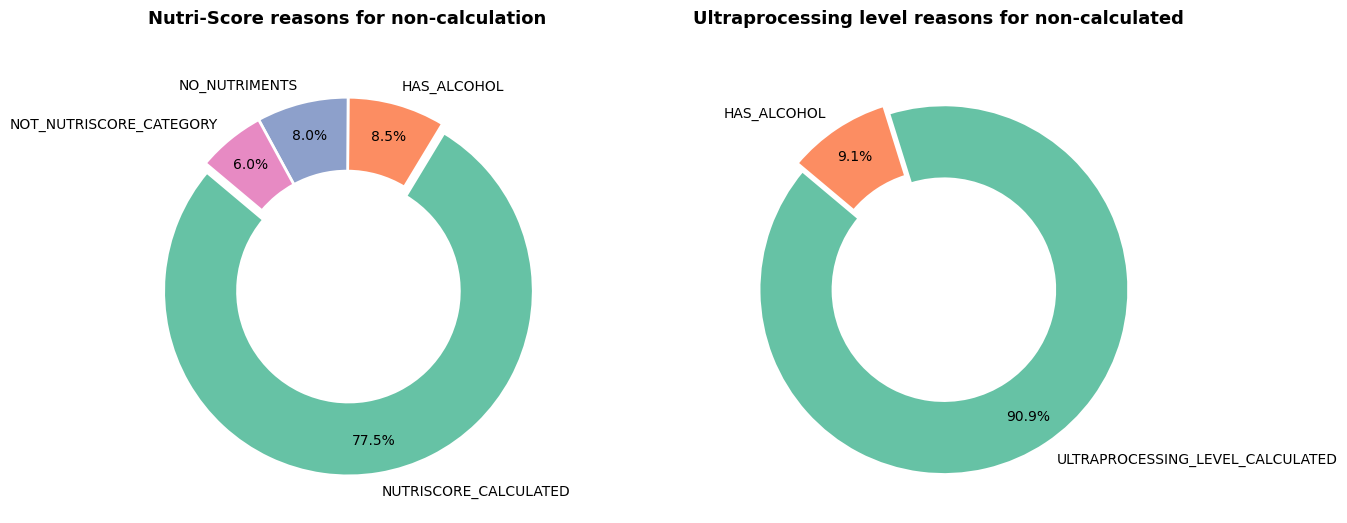

In [22]:
nutri_counts = prepare_status_counts(
    df_unique_product_catalogue, 
    score_col='nutriscore', 
    reason_col='can_nutriscore_be_calculated',
    calculated_label='NUTRISCORE_CALCULATED'
)

ultraprocessing_level_counts = prepare_status_counts(
    df_unique_product_catalogue,
    score_col='ewo_ultra_processed_punctuation',
    reason_col='can_ewo_be_calculated',
    calculated_label='ULTRAPROCESSING_LEVEL_CALCULATED'
)

fig, ax = plt.subplots(1, 2, figsize=(14,6))

plot_status_piechart(
    nutri_counts, 
    title="Nutri-Score reasons for non-calculation", 
    calculated_label='NUTRISCORE_CALCULATED',
    ax = ax[0]
)

plot_status_piechart(
    ultraprocessing_level_counts,
    title='Ultraprocessing level reasons for non-calculated',
    calculated_label='ULTRAPROCESSING_LEVEL_CALCULATED',
    ax=ax[1]
)

## 3.2. General description of dataset

### 3.2.1. Distribution of products per week and municipality

In this section, the data shown is the visibility of each category / subcategory of online grocery per each week number and postal code.

In [23]:
visibility_pivot = df_products.pivot_table(
    index=['category', 'subcategory'],
    columns=['postal_code', 'week_num'],
    values='id_product',
    aggfunc='count',
    fill_value=0,
    observed=False
)

n_weeks = df_products['week_num'].nunique()
visibility_summary = df_products.groupby(['category', 'subcategory'], observed=True).agg(
    total_appearances=('id_product', 'count'),
    bcn_avg=('id_product', lambda x: (x[df_products.loc[x.index, 'postal_code'] == 8032].count() / n_weeks).round(1)),
    montferri_avg=('id_product', lambda x: (x[df_products.loc[x.index, 'postal_code'] == 43812].count() / n_weeks).round(1))
).reset_index()

total_scraped = len(df_products)
visibility_summary['visibility_%'] = ((visibility_summary['total_appearances'] / total_scraped) * 100).round(2)

visibility_summary = visibility_summary.sort_values(by='total_appearances', ascending=False)

visibility_summary.head(15)

,category,subcategory,total_appearances,bcn_avg,montferri_avg,visibility_%
16,Azúcar caramelos y chocolate,Golosinas,117,19.3,19.7,8.39
15,Azúcar caramelos y chocolate,Chocolate,96,16.3,15.7,6.88
19,Bodega,Cerveza,56,9.7,9.0,4.01
35,Cereales y galletas,Galletas,49,8.0,8.3,3.51
4,Agua y refrescos,Isotónico y energético,48,8.0,8.0,3.44
20,Bodega,Licores,46,7.7,7.7,3.30
59,Marisco y pescado,Pescado fresco,46,7.7,7.7,3.30
55,Fruta y verdura,Verdura,41,7.3,6.3,2.94
10,Aperitivos,Frutos secos y fruta desecada,36,6.0,6.0,2.58
17,Azúcar caramelos y chocolate,Turrones,35,7.0,4.7,2.51


This table displays the most category and subcategory with more visibility of products starting to **homepage**. In addition, it displays if differs between barcelona and montferri by mean.

### 3.2.2. Promotion information of the products sample

In [24]:
df_products['has_price_discount'] = (
    df_products['previous_pvp'].notna() & 
    (df_products['previous_pvp'] > df_products['pvp'])
)

df_products['percentage_discount'] = np.where(
    df_products['has_price_discount'],
    (((df_products['previous_pvp'] - df_products['pvp']) / df_products['previous_pvp']) * 100).round(2),
    0.0
)

discount_bins = [-np.inf, 0, 10, 25, np.inf]
discount_labels = ['no_discount', 'low_discount (<=10%)', 'moderate_discount (10-25%)', 'high_discount (>25%)']

df_products['discount_tier'] = pd.cut(
    df_products['percentage_discount'],
    bins=discount_bins,
    labels=discount_labels,
    right=True
)

conditions_pack = [
    (df_products['total_units'] <= 1) | (df_products['total_units'].isna()),
    (df_products['total_units'] == 2),
    (df_products['total_units'] >= 3)
]
choices_pack = ['single_unit', 'double_pack', 'multiple_pack']

df_products['pack_format'] = np.select(conditions_pack, choices_pack, default='single_unit')

conditions_promo = [
    (df_products['has_price_discount'] == True) & (df_products['is_pack'] == True),
    (df_products['has_price_discount'] == True) & (df_products['is_pack'] == False),
    (df_products['has_price_discount'] == False) & (df_products['is_pack'] == True),
    (df_products['has_price_discount'] == False) & (df_products['is_pack'] == False)
]
choices_promo = [
    'discounted_pack',   # Pack amb descompte directe de preu
    'price_discount',    # Producte individual amb descompte
    'volume_pack',       # Format pack (sense descompte de preu addicional)
    'no_promotion'            # Producte individual a preu regular
]

df_products['promotion_type'] = np.select(conditions_promo, choices_promo, default='no_promotion')
df_products['is_promoted'] = df_products['promotion_type'] != 'no_promotion'

After all, to add context to the data, the next table contextualises the information obtained.

In [25]:
df_prod_agg = (
    df_products.groupby(
        ['week_num', 'postal_code', 'category', 'subcategory'], observed=True
    )
    .agg(
        items_obtained=('id_product', 'nunique'),
        items_with_discount=(
            'has_price_discount',
            lambda x: (x == True).sum(),
        ),
    )
    .reset_index()
)

for df in [df_prod_agg, df_aggregation]:
    df['week_num'] = df['week_num'].astype(int)
    df['postal_code'] = df['postal_code'].astype(str).str.strip().str.zfill(5)
    df['subcategory'] = (
        df['subcategory']
        .astype(str)
        .str.replace(',', '')
        .str.strip()
        .str.lower()
    )

df_prod_agg['category'] = (
    df_prod_agg['category']
    .astype(str)
    .str.replace(',', '')
    .str.strip()
    .str.lower()
)

df_aggregation_clean = df_aggregation.drop(
    columns=['category'], errors='ignore'
)

df_context = pd.merge(
    df_prod_agg,
    df_aggregation_clean,
    on=['week_num', 'postal_code', 'subcategory'],
    how='left',
)

df_context['%coverage'] = np.where(
    df_context['total_items'] > 0,
    (df_context['items_obtained'] / df_context['total_items']) * 100,
    0
)

df_context['%products under discount'] = np.where(
    df_context['items_obtained'] > 0,
    (df_context['items_with_discount'] / df_context['items_obtained']) * 100,
    0,
)

df_context['%coverage'] = df_context['%coverage'].round(2)
df_context['%products under discount'] = df_context['%products under discount'].round(2)

columns_order = [
    'week_num',
    'postal_code',
    'category',
    'subcategory',
    'items_obtained',
    'total_items',
    'items_with_discount',
    '%coverage',
    '%products under discount',
]

final_cols = [col for col in columns_order if col in df_context.columns]
df_context_summary = df_context[final_cols]

df_context_summary.sort_values('items_obtained', ascending=False)

,week_num,postal_code,category,subcategory,items_obtained,total_items,items_with_discount,%coverage,%products under discount
213,41,43812,azúcar caramelos y chocolate,golosinas,23,24,2,95.83,8.70
271,42,08032,azúcar caramelos y chocolate,golosinas,22,24,2,91.67,9.09
324,42,43812,azúcar caramelos y chocolate,golosinas,22,24,2,91.67,9.09
153,41,08032,azúcar caramelos y chocolate,golosinas,22,23,2,95.65,9.09
212,41,43812,azúcar caramelos y chocolate,chocolate,16,69,5,23.19,31.25
...,...,...,...,...,...,...,...,...,...
88,40,43812,bodega,tinto de verano y sangría,1,8,1,12.50,100.00
84,40,43812,azúcar caramelos y chocolate,golosinas,1,19,0,5.26,0.00
18,40,08032,bodega,tinto de verano y sangría,1,8,1,12.50,100.00
20,40,08032,bodega,vino tinto,1,32,1,3.12,100.00


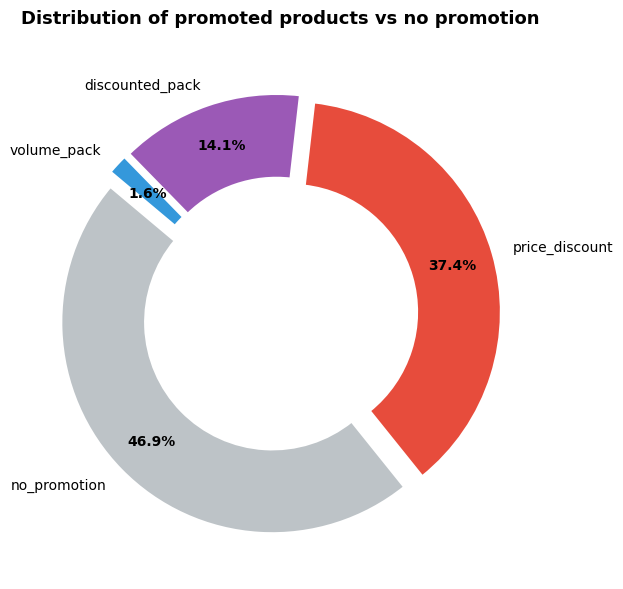

In [26]:
def plot_promotion_overall_donut(df):
    counts = df['promotion_type'].value_counts()
    
    # Paleta de colors: Gris neutre per a regular, colors vius per a promocions
    color_map = {
        'no_promotion': '#bdc3c7',          # Gris neutre (sense promoció)
        'price_discount': '#e74c3c',   # Vermell (descompte de preu)
        'volume_pack': '#3498db',      # Blau (format pack / volum)
        'discounted_pack': '#9b59b6'   # Lila (pack + descompte de preu)
    }
    
    colors = [color_map.get(x, '#7f8c8d') for x in counts.index]
    # Seballem lleugerament les porcions promocionades
    explode = [0.05 if x != 'regular' else 0 for x in counts.index]
    
    fig, ax = plt.subplots(figsize=(8, 6))
    wedges, texts, autotexts = ax.pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.8,
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
    )
    
    plt.setp(autotexts, size=10, weight="bold")
    ax.set_title("Distribution of promoted products vs no promotion", fontsize=13, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

# Execució
plot_promotion_overall_donut(df_products)

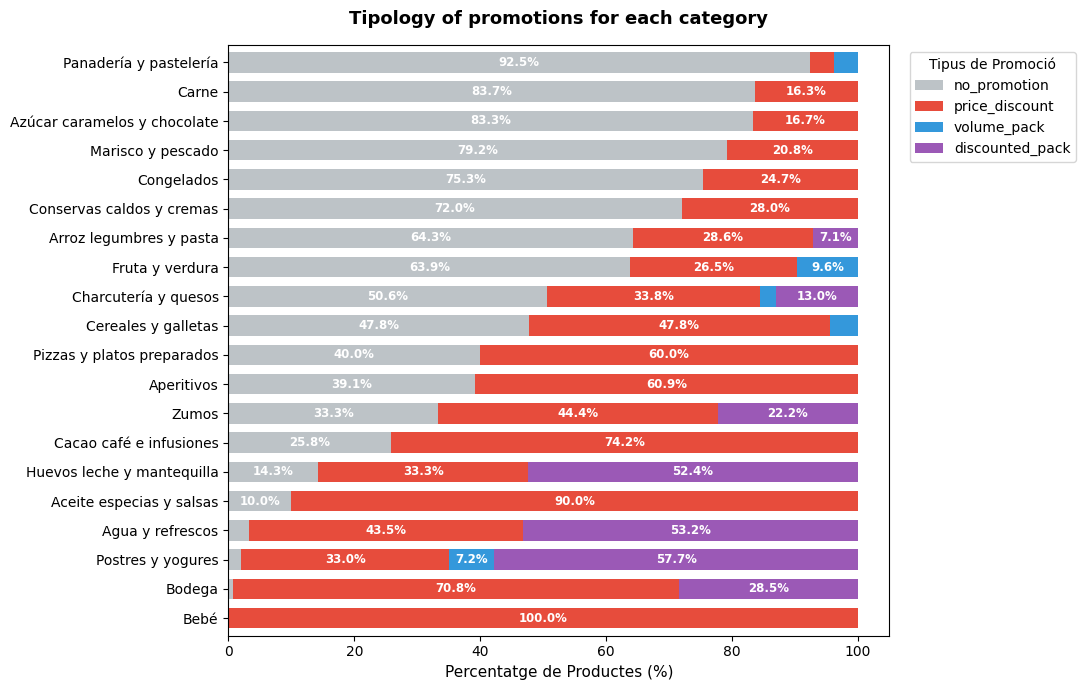

In [27]:
def plot_promotion_by_category_stacked(df):
    # Taula creuada normalitzada al 100% per categoria
    ct = pd.crosstab(df['category'], df['promotion_type'], normalize='index') * 100
    
    # Ordre lògic de les columnes
    desired_order = ['no_promotion', 'price_discount', 'volume_pack', 'discounted_pack']
    cols = [c for c in desired_order if c in ct.columns]
    ct = ct[cols]
    
    # Ordenem les categories per percentatge de 'regular' de menor a major (més promocionades a dalt)
    if 'no_promotion' in ct.columns:
        ct = ct.sort_values(by='no_promotion', ascending=True)
    
    color_map = {
        'no_promotion': '#bdc3c7',          # Gris neutre
        'price_discount': '#e74c3c',   # Vermell
        'volume_pack': '#3498db',      # Blau
        'discounted_pack': '#9b59b6'   # Lila
    }
    colors = [color_map[c] for c in ct.columns]
    
    fig, ax = plt.subplots(figsize=(11, 7))
    ct.plot(kind='barh', stacked=True, color=colors, ax=ax, width=0.7)
    
    # Afegir percentatges a l'interior de les barres (només si el segment és > 5%)
    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        if width > 5:
            x, y = p.get_xy() 
            ax.text(x + width/2, y + height/2, f"{width:.1f}%", 
                    ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
            
    ax.set_title("Tipology of promotions for each category", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Percentatge de Productes (%)", fontsize=11)
    ax.set_ylabel("")
    ax.legend(title="Tipus de Promoció", bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# Execució
plot_promotion_by_category_stacked(df_products)

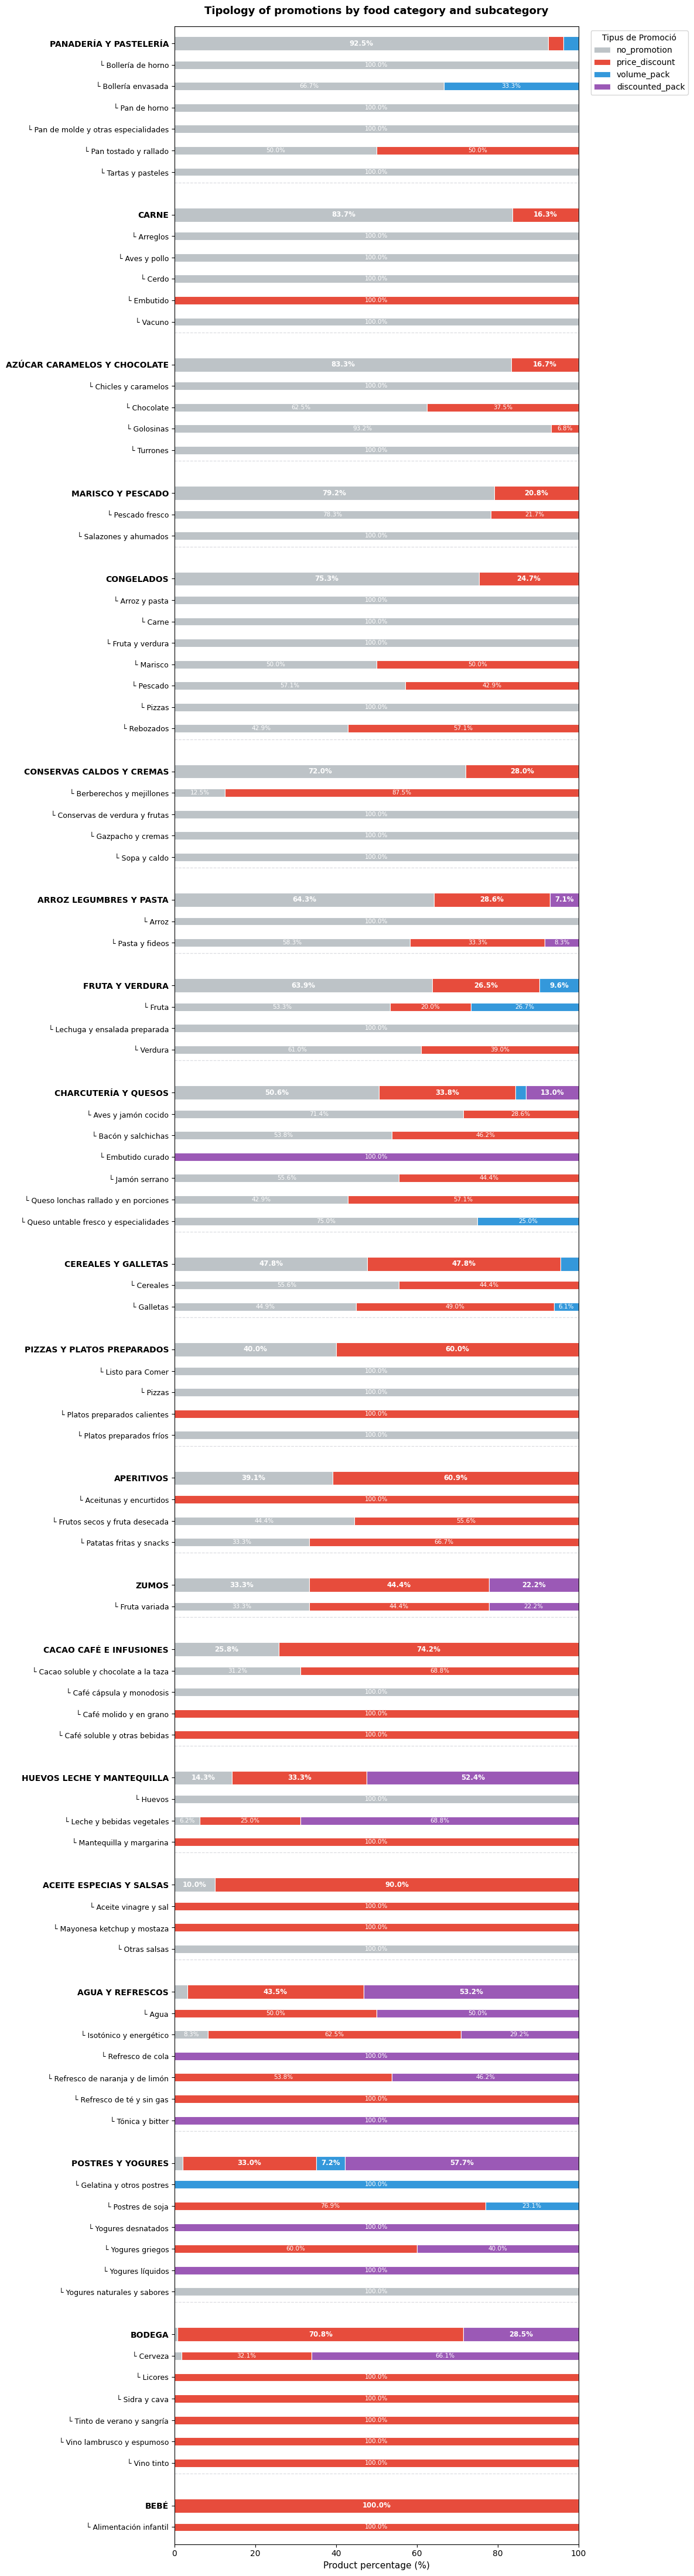

In [28]:
def plot_promotion_by_category_and_subcategory(df, include_category_totals=True):
    # 1. Càlcul de taules creuades i neteja de categories buides (sense productes)
    ct_sub = pd.crosstab([df['category'], df['subcategory']], df['promotion_type'], normalize='index') * 100
    ct_cat = pd.crosstab(df['category'], df['promotion_type'], normalize='index') * 100

    # Eliminem qualsevol fila que no tingui dades (evita l'espai buit a la part superior)
    ct_sub = ct_sub.dropna(how='all')
    ct_cat = ct_cat.dropna(how='all')

    desired_order = ['no_promotion', 'price_discount', 'volume_pack', 'discounted_pack']
    cols = [c for c in desired_order if c in ct_cat.columns]

    # Ordenem les categories pel percentatge de 'no_promotion'
    if 'no_promotion' in ct_cat.columns:
        cat_order = ct_cat['no_promotion'].sort_values(ascending=False).index
    else:
        cat_order = ct_cat.index

    # Mapeig de colors
    color_map = {
        'no_promotion': '#bdc3c7',     # Gris neutre
        'price_discount': '#e74c3c',   # Vermell
        'volume_pack': '#3498db',      # Blau
        'discounted_pack': '#9b59b6'   # Lila
    }
    colors = [color_map.get(c, '#7f8c8d') for c in cols]

    y_positions = []
    y_labels = []
    bar_heights = []
    is_main_list = []
    data_rows = []

    current_y = 0
    cat_separator_positions = []

    # 2. Construcció de la jerarquia (de baix a dalt)
    for i, cat in enumerate(reversed(cat_order)):
        # A) Subcategories
        if cat in ct_sub.index.get_level_values(0):
            sub_data = ct_sub.loc[cat]
            for subcat in reversed(sub_data.index):
                data_rows.append(sub_data.loc[subcat, cols].values)
                y_positions.append(current_y)
                y_labels.append(f"  └ {subcat}")
                bar_heights.append(0.38) # Barra més fina per a subcategoria
                is_main_list.append(False)
                current_y += 1.0

        # B) Barra resum de la Categoria Principal
        if include_category_totals and cat in ct_cat.index:
            data_rows.append(ct_cat.loc[cat, cols].values)
            y_positions.append(current_y)
            y_labels.append(str(cat).upper())
            bar_heights.append(0.65) # Barra més gruixuda per a categoria principal
            is_main_list.append(True)
            current_y += 1.2

        # Afegim línia de separació si no és l'últim bloc (el de més a dalt)
        if i < len(cat_order) - 1:
            cat_separator_positions.append(current_y + 0.3)
            current_y += 0.8 # Espai extra entre blocs de categories

    if len(y_positions) == 0:
        print("No hi ha dades per mostrar.")
        return

    data_matrix = np.array(data_rows)

    # Alçada dinàmica de la figura segons les barres reals
    fig_height = max(6, len(y_positions) * 0.45)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    # Dibuixem les barres acumulades
    lefts = np.zeros(len(y_positions))
    for col_idx, col_name in enumerate(cols):
        widths = data_matrix[:, col_idx]
        bars = ax.barh(
            y_positions, 
            widths, 
            left=lefts, 
            height=bar_heights, 
            color=colors[col_idx], 
            label=col_name,
            edgecolor='white',
            linewidth=0.8
        )

        # Anotació dels percentatges (> 5.5%)
        for idx, (bar, width) in enumerate(zip(bars, widths)):
            if not np.isnan(width) and width > 5.5:
                y_pos = bar.get_y() + bar.get_height() / 2
                x_pos = lefts[idx] + width / 2
                font_weight = 'bold' if is_main_list[idx] else 'normal'
                font_size = 8.5 if is_main_list[idx] else 7.5
                ax.text(
                    x_pos, y_pos, f"{width:.1f}%", 
                    ha='center', va='center', color='white', 
                    fontweight=font_weight, fontsize=font_size
                )
        lefts += widths

    # Dibuixem les línies discontínues de separació
    for sep_y in cat_separator_positions:
        ax.axhline(y=sep_y, color='#dcdde1', linestyle='--', linewidth=0.9)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels, fontsize=9)

    # Negreta per a les categories principals a l'eix Y
    for tick_label, is_main in zip(ax.get_yticklabels(), is_main_list):
        if is_main:
            tick_label.set_fontweight('bold')
            tick_label.set_fontsize(10)

    # AJUST CLAU: Limitem l'eix Y exactament des del primer fins a l'últim element real
    ax.set_ylim(min(y_positions) - 0.8, max(y_positions) + 0.8)

    ax.set_title("Tipology of promotions by food category and subcategory", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Product percentage (%)", fontsize=11)
    ax.set_xlim(0, 100)
    ax.legend(title="Tipus de Promoció", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

# Execució
plot_promotion_by_category_and_subcategory(df_products)

In [61]:
def get_mean_ci(series, cl: float = CL):
    """
    Interval de confiança per a una mitjana (variable contínua)
    """
    s = series.dropna()
    n = len(s)
    if n < 2:
        return "N/A"
    
    mean = np.mean(s)
    sem = stats.sem(s) # Standard Error of the Mean (scipy)
    
    # Interval de confiança del 95% amb t de Student perquè és una variable contínua, amb l'error estandard de la mitjana
    ci_lower, ci_upper = stats.t.interval(cl, df=n-1, loc=mean, scale=sem)
    
    return f"{mean:.2f}% [{ci_lower:.2f}%, {ci_upper:.2f}%]"

def get_proportion_ci(series, cl: float = CL):
    """
    Interval de confiança per a una proporció / percentatge (variable binaria)
    """
    s = series.dropna()
    n = len(s)
    if n == 0:
        return "N/A"
    
    p = np.mean(s) # Proporció (de 0 a 1)
    se = np.sqrt((p * (1 - p)) / n) # Error estàndard de la proporció
    
    # Interval de confiança del 95% amb distribució Normal perque els valors son proporcions que són 0 o 1.
    ci_lower, ci_upper = stats.norm.interval(cl, loc=p, scale=se)
    
    # Convertim a percentatge
    pct = p * 100
    ci_l = max(0, ci_lower * 100) # Evitem valors negatius
    ci_u = min(100, ci_upper * 100)
    
    return f"{pct:.1f}% [{ci_l:.1f}%, {ci_u:.1f}%]"

items_table = []
for (cat, subcat), group in df_products.groupby(['category', 'subcategory'], observed=True):
    total_n = len(group)
    homepage_n = group['title_category_main_page'].notna().sum() # no se a que es refereix????
    
    # 1. Products Discounted (%)
    disc_prop_str = get_proportion_ci(group['has_price_discount'])
    
    # 2. Magnitude of Discount (% Change)
    disc_mag_str = get_mean_ci(group['percentage_discount'])
    
    # 3. Products on Multi-buys / packs (%)
    packs_prop_str = get_proportion_ci(group['is_pack'])
    
    # 4. Units in Multi-buys (Mean; SD)
    pack_units = group[group['is_pack'] == True]['total_units']
    if len(pack_units) > 0:
        units_mean_sd = f"{pack_units.mean():.2f} (SD: {pack_units.std():.2f})"
    else:
        units_mean_sd = "N/A"
        
    items_table.append({
        'Category': cat,
        'Subcategory': subcat,
        'Homepage (n)': homepage_n,
        'Total (n)': total_n,
        'Products Discounted (%; 95% CI)': disc_prop_str,
        'Magnitude of Discount (% Change; 95% CI)': disc_mag_str,
        'Products on Multi-buys (%; 95% CI)': packs_prop_str,
        'Units in Multi-buys (Mean; SD)': units_mean_sd
    })

table_results_df = pd.DataFrame(items_table)
table_results_df

/usr/local/lib/python3.13/dist-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/usr/local/lib/python3.13/dist-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


,Category,Subcategory,Homepage (n),Total (n),Products Discounted (%; 95% CI),Magnitude of Discount (% Change; 95% CI),Products on Multi-buys (%; 95% CI),Units in Multi-buys (Mean; SD)
0,Aceite especias y salsas,Aceite vinagre y sal,28,28,"100.0% [0.0%, 100.0%]","3.63% [3.16%, 4.09%]","0.0% [0.0%, 100.0%]",N/A
1,Aceite especias y salsas,Mayonesa ketchup y mostaza,8,8,"100.0% [0.0%, 100.0%]","17.54% [13.74%, 21.35%]","0.0% [0.0%, 100.0%]",N/A
2,Aceite especias y salsas,Otras salsas,4,4,"0.0% [0.0%, 100.0%]","0.00% [nan%, nan%]","0.0% [0.0%, 100.0%]",N/A
3,Agua y refrescos,Agua,8,8,"100.0% [0.0%, 100.0%]","8.00% [nan%, nan%]","50.0% [15.4%, 84.6%]",6.00 (SD: 0.00)
4,Agua y refrescos,Isotónico y energético,48,48,"91.7% [83.8%, 99.5%]","15.79% [14.01%, 17.57%]","29.2% [16.3%, 42.0%]",4.57 (SD: 1.45)
...,...,...,...,...,...,...,...,...
73,Postres y yogures,Yogures desnatados,24,24,"100.0% [0.0%, 100.0%]","3.23% [nan%, nan%]","100.0% [0.0%, 100.0%]",4.00 (SD: 0.00)
74,Postres y yogures,Yogures griegos,20,20,"100.0% [0.0%, 100.0%]","5.15% [4.80%, 5.51%]","40.0% [18.5%, 61.5%]",6.00 (SD: 0.00)
75,Postres y yogures,Yogures líquidos,24,24,"100.0% [0.0%, 100.0%]","12.49% [10.40%, 14.59%]","100.0% [0.0%, 100.0%]",11.00 (SD: 1.02)
76,Postres y yogures,Yogures naturales y sabores,2,2,"0.0% [0.0%, 100.0%]","0.00% [nan%, nan%]","0.0% [0.0%, 100.0%]",N/A


#### 3.2.2.1. Promotion types and objective variables

TODO: aqui quan tingui planet score pos llavors ja mirarem a veure com incloure-ho...

Els aliments ultraprocessats (EWÖ 4) o de pitjor qualitat nutricional (Nutri-Score D/E) tenen més probabilitat d'estar en descompte que els aliments frescos o saludables?

In [30]:
pd.crosstab(
    df_products['nutriscore'], 
    df_products['has_price_discount'], 
    normalize='index'
) * 100

has_price_discount,False,True
nutriscore,,
A,55.000000,45.000000
B,36.363636,63.636364
C,37.288136,62.711864
D,43.961353,56.038647
E,63.425926,36.574074


In [31]:
pd.crosstab(
    df_products['ewo_ultra_processed_punctuation'], 
    df_products['has_price_discount'], 
    normalize='index'
) * 100

has_price_discount,False,True
ewo_ultra_processed_punctuation,,
1.0,76.699029,23.300971
2.0,35.652174,64.347826
3.0,47.239264,52.760736
4.0,51.088348,48.911652


Quan un supermercat fa un descompte molt agressiu (>25%), ho fa sobre productes de baixa qualitat (p. ex., galetes o refrescos) o sobre aliments saludables?

In [32]:
pd.crosstab(
    df_products['promotion_type'], 
    df_products['nutriscore'], 
    normalize='index'
) * 100

nutriscore,A,B,C,D,E
promotion_type,,,,,
discounted_pack,17.500000,7.500000,22.500000,15.000000,37.500000
no_promotion,15.970962,4.355717,14.519056,16.152450,49.001815
price_discount,11.702128,7.978723,29.787234,24.468085,26.063830
volume_pack,0.000000,0.000000,57.142857,14.285714,28.571429


In [33]:
pd.crosstab(
    df_products['promotion_type'], 
    df_products['ewo_ultra_processed_punctuation'], 
    normalize='index'
) * 100

ewo_ultra_processed_punctuation,1.0,2.0,3.0,4.0
promotion_type,,,,
discounted_pack,2.500000,13.750000,6.250000,77.500000
no_promotion,22.970904,6.278714,11.485452,59.264931
price_discount,10.232558,12.093023,17.674419,60.000000
volume_pack,36.363636,0.000000,9.090909,54.545455


S'utilitza l'estratègia de venda en volum/multipack per incentivar el consum massiu de productes ultraprocessats?

In [34]:
pd.crosstab(
    df_products['pack_format'], 
    df_products['nutriscore'], 
    normalize='index'
) * 100

nutriscore,A,B,C,D,E
pack_format,,,,,
double_pack,0.000000,0.000000,0.000000,23.529412,76.470588
multiple_pack,17.834395,7.643312,28.025478,14.012739,32.484076
single_unit,14.239482,5.825243,20.711974,19.525351,39.697950


In [35]:
pd.crosstab(
    df_products['pack_format'], 
    df_products['ewo_ultra_processed_punctuation'], 
    normalize='index'
) * 100

ewo_ultra_processed_punctuation,1.0,2.0,3.0,4.0
pack_format,,,,
double_pack,0.000000,0.000000,0.000000,100.000000
multiple_pack,2.547771,14.012739,7.643312,75.796178
single_unit,18.515124,8.524290,13.840513,59.120073


Quin és el percentatge mitjà de rebaixa que rep un aliment Nutri-Score A en comparació amb un Nutri-Score E?

In [36]:
# Resum de la magnitud del descompte per Nutri-Score (només productes amb descompte)
df_discounted = df_products[df_products['has_price_discount'] == True]

df_discounted.groupby('nutriscore')['percentage_discount'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Std='std'
).round(2)

,Count,Mean,Median,Std
nutriscore,,,,
A,72,5.75,4.00,3.67
B,42,8.77,10.00,4.72
C,148,10.14,7.63,6.88
D,116,11.48,9.05,7.83
E,158,12.53,9.09,8.27


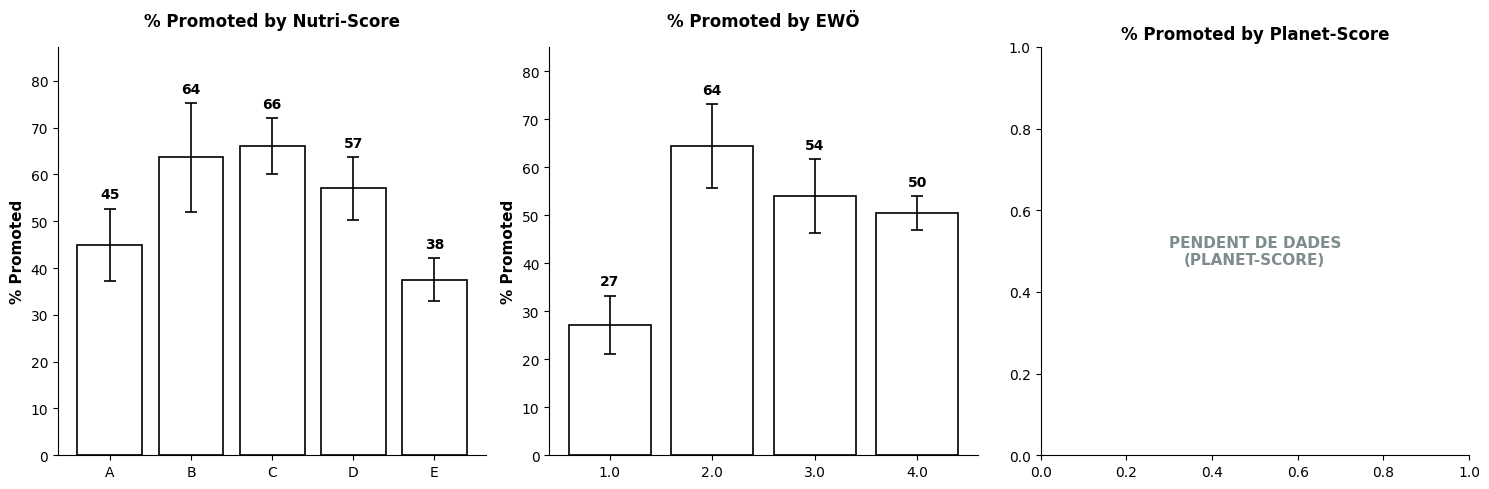

In [60]:
def calculate_promotion_proportions(series_promo, cl: float = CL):
    """Calcula el percentatge i els marges d'error de l'interval de confiança del 95%."""
    s = series_promo.dropna()
    n = len(s)
    if n == 0:
        return 0.0, 0.0, 0.0
    p = s.mean()
    if p == 0 or p == 1:
        return p * 100, 0.0, 0.0
    
    se = np.sqrt(p * (1 - p) / n)
    ci_l, ci_u = stats.norm.interval(cl, loc=p, scale=se)
    ci_l = max(0.0, ci_l)
    ci_u = min(1.0, ci_u)
    
    pct = p * 100
    err_low = (p - ci_l) * 100
    err_high = (ci_u - p) * 100
    return pct, err_low, err_high

def plot_promoted_percentage_by_score(df):
    """
    Genera el panell de gràfics de barres amb intervals de confiança del 95% 
    segons l'estil sol·licitat per la professora.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Configuration for each indicator
    configs = [
        {'col': 'nutriscore', 'name': 'Nutri-Score', 'levels': ['A', 'B', 'C', 'D', 'E'], 'ax_idx': 0},
        {'col': 'ewo_ultra_processed_punctuation', 'name': 'EWÖ', 'levels': [1.0, 2.0, 3.0, 4.0], 'ax_idx': 1},
        {'col': 'planetscore', 'name': 'Planet-Score', 'levels': ['A', 'B', 'C', 'D', 'E'], 'ax_idx': 2}
    ]
    
    for cfg in configs:
        ax = axes[cfg['ax_idx']]
        col = cfg['col']
        
        has_data = col in df.columns and df[col].notna().sum() > 0
        
        if not has_data:
            ax.text(0.5, 0.5, f"PENDENT DE DADES\n({cfg['name'].upper()})", 
                    ha='center', va='center', fontsize=11, fontweight='bold', color='#7f8c8d')
            ax.set_title(f"% Promoted by {cfg['name']}", fontweight='bold', fontsize=12)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            continue
            
        # Calculate stats for each level
        pcts, errs_low, errs_high, x_labels = [], [], [], []
        for level in cfg['levels']:
            sub = df[df[col] == level]['is_promoted']
            pct, err_l, err_h = calculate_promotion_proportions(sub)
            pcts.append(pct)
            errs_low.append(err_l)
            errs_high.append(err_h)
            x_labels.append(str(level))
            
        x = np.arange(len(x_labels))
        
        # Plot bars matching professor's style (black outline, error bars, no top/right spines)
        bars = ax.bar(
            x, pcts, 
            yerr=[errs_low, errs_high], 
            capsize=4, 
            color='white', 
            edgecolor='black', 
            linewidth=1.2,
            error_kw=dict(ecolor='black', lw=1.2, capsize=4, capthick=1.2)
        )
        
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_ylabel('% Promoted', fontsize=11, fontweight='bold')
        ax.set_title(f"% Promoted by {cfg['name']}", fontweight='bold', fontsize=12, pad=15)
        
        max_y = max([p + e for p, e in zip(pcts, errs_high)]) if len(pcts) > 0 else 50
        ax.set_ylim(0, max(50, max_y + 12))
        
        # Add rounded percentage value above error bars
        for i, (p, e_h) in enumerate(zip(pcts, errs_high)):
            if p > 0:
                ax.text(i, p + e_h + 1.5, f"{int(round(p))}", ha='center', va='bottom', fontsize=10, fontweight='bold')
                
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()

# Execució de la funció
plot_promoted_percentage_by_score(df_products)


## 3.3. General distribution of objective variables

Nutri-Score: Mapegem les lletres a un rang numèric ordinal ($A=1, B=2, C=3, D=4, E=5$), on valors més baixos indueixen una millor qualitat nutricional.EWÖ (Ultraprocessament): Fem servir la puntuació directa d'1 a 4 ($1=\text{no processat}$, $4=\text{ultraprocessat}$).Planet-Score: Deixem la lògica preparada per mapejar la nota quan s'integrin les dades externes. Si la columna conté NaN, la funció dibuixa automàticament un panell reservat de placeholder sense generar cap error.

In [38]:
nutri_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
df_products['nutriscore_num'] = df_products['nutriscore'].map(nutri_map)

has_planet_data = df_products['planetscore'].notna().sum() > 0
    
if has_planet_data:
    planet_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
    df_products['planetscore_num'] = df_products['planetscore'].map(planet_map)

### 3.3.1. Plotting general distribution of objective variables

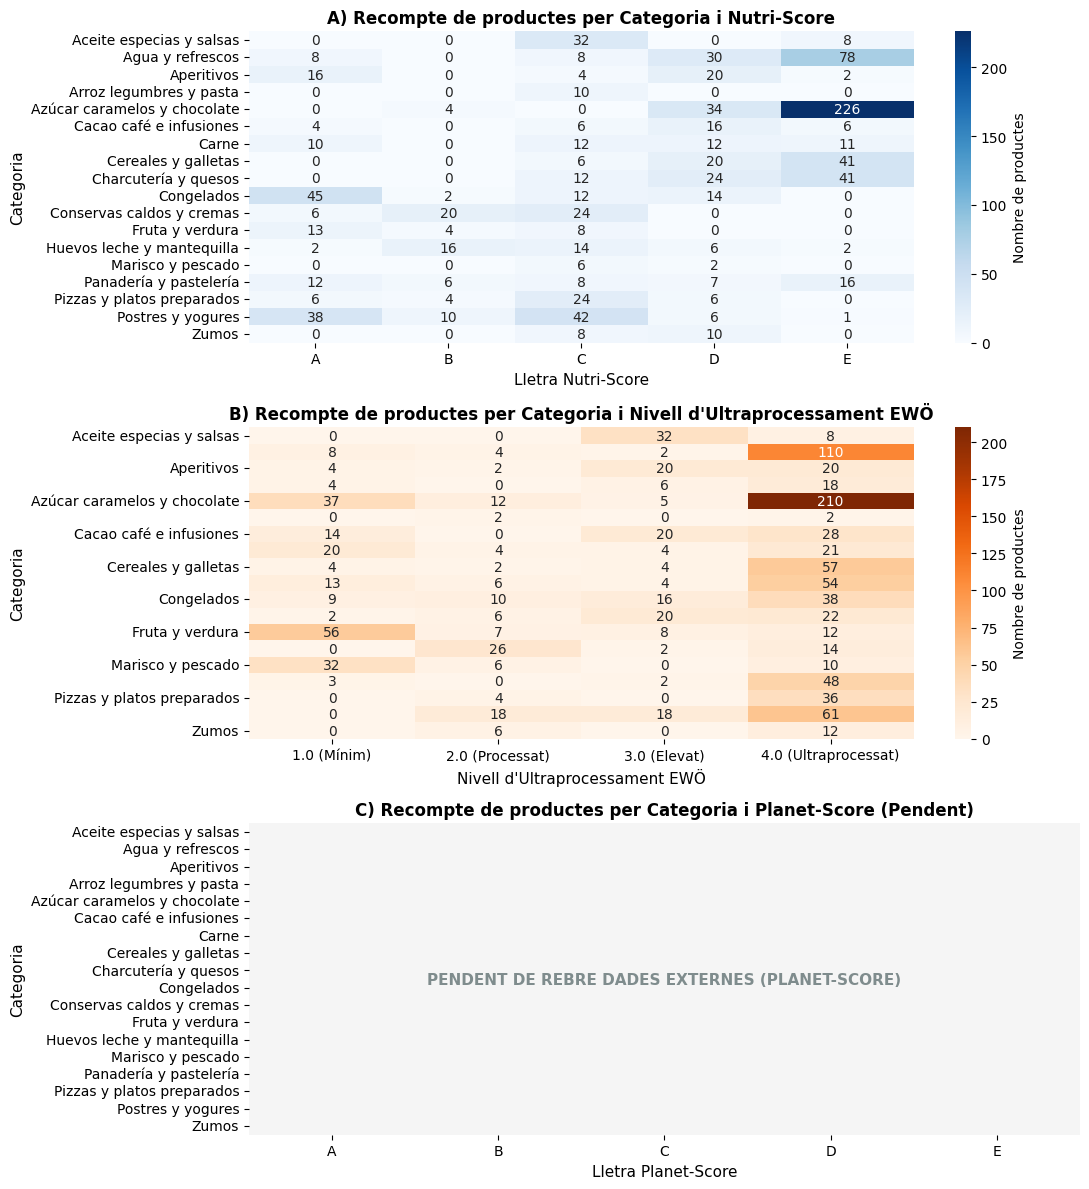

In [39]:
def plot_score_heatmaps_by_category(df):
    """Genera un panell de 3 heatmaps de recompte de productes per Categoria i per

    cada indicador (Nutri-Score, EWÖ i Planet-Score).
    """
    has_planet = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    # 1. Taules creuades de Recompte (Categoria x Nivell)
    ct_nutri = (
        pd.crosstab(df['category'], df['nutriscore'])
        .reindex(columns=['A', 'B', 'C', 'D', 'E'])
        .fillna(0)
        .astype(int)
    )

    ct_ewo = (
        pd.crosstab(
            df['category'], df['ewo_ultra_processed_punctuation']
        )
        .reindex(columns=[1.0, 2.0, 3.0, 4.0])
        .fillna(0)
        .astype(int)
    )
    ct_ewo.columns = [
        '1.0 (Mínim)',
        '2.0 (Processat)',
        '3.0 (Elevat)',
        '4.0 (Ultraprocessat)',
    ]

    # 2. Configuració de la figura
    fig, axes = plt.subplots(3, 1, figsize=(11, 12))

    # --- Heatmap 1: Nutri-Score ---
    sns.heatmap(
        ct_nutri,
        ax=axes[0],
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar_kws={'label': 'Nombre de productes'},
    )
    axes[0].set_title(
        'A) Recompte de productes per Categoria i Nutri-Score',
        fontweight='bold',
        fontsize=12,
    )
    axes[0].set_xlabel('Lletra Nutri-Score', fontsize=11)
    axes[0].set_ylabel('Categoria', fontsize=11)

    # --- Heatmap 2: EWÖ ---
    sns.heatmap(
        ct_ewo,
        ax=axes[1],
        annot=True,
        fmt='d',
        cmap='Oranges',
        cbar_kws={'label': 'Nombre de productes'},
    )
    axes[1].set_title(
        "B) Recompte de productes per Categoria i Nivell d'Ultraprocessament"
        ' EWÖ',
        fontweight='bold',
        fontsize=12,
    )
    axes[1].set_xlabel("Nivell d'Ultraprocessament EWÖ", fontsize=11)
    axes[1].set_ylabel('Categoria', fontsize=11)

    # --- Heatmap 3: Planet-Score ---
    if has_planet:
        ct_planet = (
            pd.crosstab(df['category'], df['planetscore'])
            .reindex(columns=['A', 'B', 'C', 'D', 'E'])
            .fillna(0)
            .astype(int)
        )
        sns.heatmap(
            ct_planet,
            ax=axes[2],
            annot=True,
            fmt='d',
            cmap='Greens',
            cbar_kws={'label': 'Nombre de productes'},
        )
        axes[2].set_title(
            'C) Recompte de productes per Categoria i Planet-Score',
            fontweight='bold',
            fontsize=12,
        )
        axes[2].set_xlabel('Lletra Planet-Score', fontsize=11)
        axes[2].set_ylabel('Categoria', fontsize=11)
    else:
        dummy_df = pd.DataFrame(
            0, index=ct_nutri.index, columns=['A', 'B', 'C', 'D', 'E']
        )
        sns.heatmap(
            dummy_df, ax=axes[2], cmap=['#f5f5f5'], cbar=False, annot=False
        )
        axes[2].text(
            0.5,
            0.5,
            'PENDENT DE REBRE DADES EXTERNES (PLANET-SCORE)',
            ha='center',
            va='center',
            fontsize=11,
            fontweight='bold',
            color='#7f8c8d',
            transform=axes[2].transAxes,
        )
        axes[2].set_title(
            'C) Recompte de productes per Categoria i Planet-Score (Pendent)',
            fontweight='bold',
            fontsize=12,
        )
        axes[2].set_ylabel('Categoria', fontsize=11)
        axes[2].set_xlabel('Lletra Planet-Score', fontsize=11)

    plt.tight_layout()
    plt.show()


# Executar
plot_score_heatmaps_by_category(df_products)

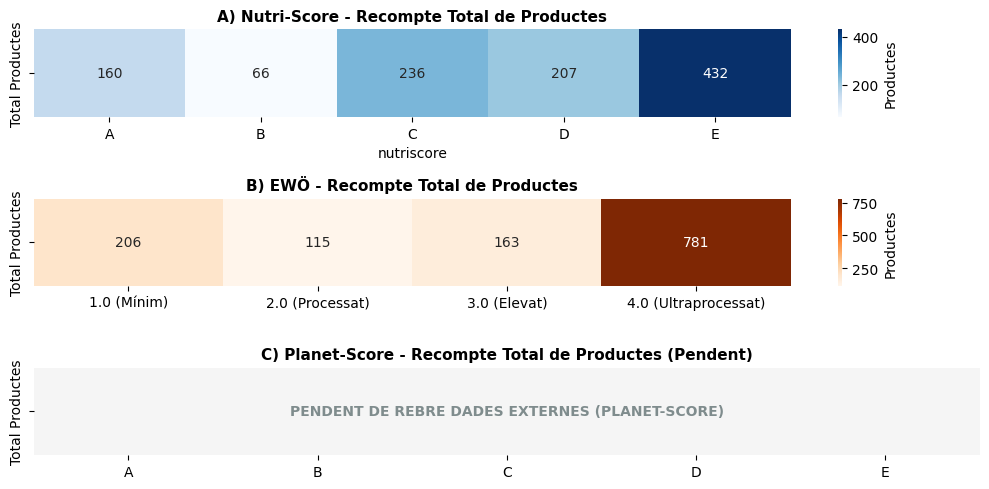

In [40]:
def plot_overall_score_heatmaps_1d(df):
    """Genera 3 heatmaps de tira horitzontal (1D) amb el recompte total absolut

    de productes per a cada lletra o nivell d'indicador.
    """
    has_planet = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    # Recomptes totals
    nutri_tot = (
        df['nutriscore']
        .value_counts()
        .reindex(['A', 'B', 'C', 'D', 'E'])
        .fillna(0)
        .astype(int)
    )
    df_nutri_tot = pd.DataFrame(
        [nutri_tot.values],
        index=['Total Productes'],
        columns=nutri_tot.index,
    )

    ewo_tot = (
        df['ewo_ultra_processed_punctuation']
        .value_counts()
        .reindex([1.0, 2.0, 3.0, 4.0])
        .fillna(0)
        .astype(int)
    )
    df_ewo_tot = pd.DataFrame(
        [ewo_tot.values],
        index=['Total Productes'],
        columns=[
            '1.0 (Mínim)',
            '2.0 (Processat)',
            '3.0 (Elevat)',
            '4.0 (Ultraprocessat)',
        ],
    )

    fig, axes = plt.subplots(3, 1, figsize=(10, 5))

    # Nutri-Score
    sns.heatmap(
        df_nutri_tot,
        ax=axes[0],
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar_kws={'label': 'Productes'},
    )
    axes[0].set_title(
        'A) Nutri-Score - Recompte Total de Productes',
        fontweight='bold',
        fontsize=11,
    )

    # EWÖ
    sns.heatmap(
        df_ewo_tot,
        ax=axes[1],
        annot=True,
        fmt='d',
        cmap='Oranges',
        cbar_kws={'label': 'Productes'},
    )
    axes[1].set_title(
        'B) EWÖ - Recompte Total de Productes', fontweight='bold', fontsize=11
    )

    # Planet-Score
    if has_planet:
        planet_tot = (
            df['planetscore']
            .value_counts()
            .reindex(['A', 'B', 'C', 'D', 'E'])
            .fillna(0)
            .astype(int)
        )
        df_planet_tot = pd.DataFrame(
            [planet_tot.values],
            index=['Total Productes'],
            columns=planet_tot.index,
        )
        sns.heatmap(
            df_planet_tot,
            ax=axes[2],
            annot=True,
            fmt='d',
            cmap='Greens',
            cbar_kws={'label': 'Productes'},
        )
        axes[2].set_title(
            'C) Planet-Score - Recompte Total de Productes',
            fontweight='bold',
            fontsize=11,
        )
    else:
        dummy_df = pd.DataFrame(
            [[0] * 5],
            index=['Total Productes'],
            columns=['A', 'B', 'C', 'D', 'E'],
        )
        sns.heatmap(
            dummy_df, ax=axes[2], cmap=['#f5f5f5'], cbar=False, annot=False
        )
        axes[2].text(
            0.5,
            0.5,
            'PENDENT DE REBRE DADES EXTERNES (PLANET-SCORE)',
            ha='center',
            va='center',
            fontsize=10,
            fontweight='bold',
            color='#7f8c8d',
            transform=axes[2].transAxes,
        )
        axes[2].set_title(
            'C) Planet-Score - Recompte Total de Productes (Pendent)',
            fontweight='bold',
            fontsize=11,
        )

    plt.tight_layout()
    plt.show()


# Executar
plot_overall_score_heatmaps_1d(df_products)

### 3.3.2. Plotting objective variables in comparison with postal code and week number

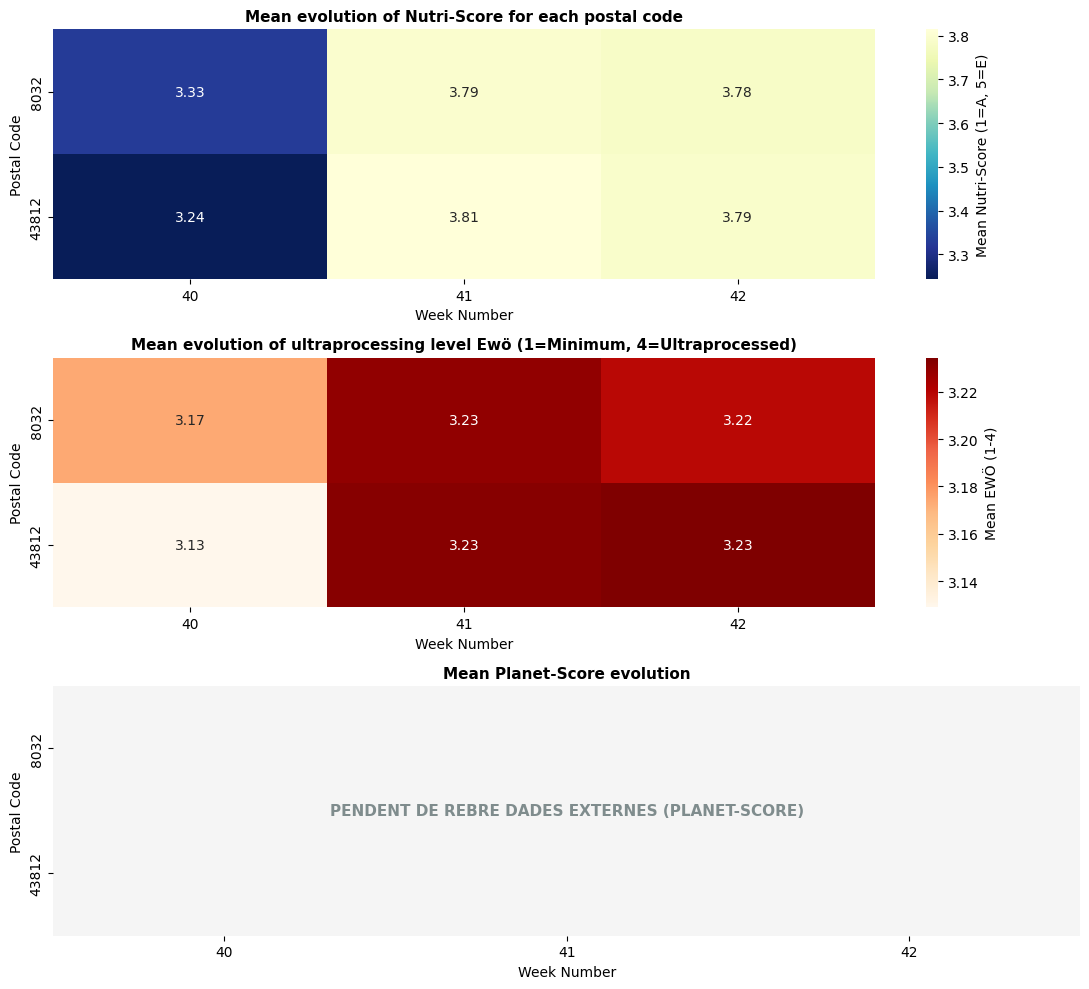

In [41]:
def plot_temporal_heatmaps(df):
    """
    Genera un panell integrat de heatmaps per analitzar l'evolució temporal
    de Nutri-Score, EWÖ i Planet-Score amb l'eix X repetit a cada gràfic.
    """

    # 2. Creació de les taules dinàmiques
    pivot_nutri = df.pivot_table(
        index='postal_code', 
        columns='week_num', 
        values='nutriscore_num', 
        aggfunc='mean'
    )
    
    pivot_ewo = df.pivot_table(
        index='postal_code', 
        columns='week_num', 
        values='ewo_ultra_processed_punctuation', 
        aggfunc='mean'
    )

    # 3. CANVI CLAU 1: sharex=False i ampliem lleugerament l'alçada (figsize=(11, 10))
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=False)

    # --- Heatmap 1: Nutri-Score ---
    sns.heatmap(
        pivot_nutri, 
        ax=axes[0], 
        annot=True, 
        fmt=".2f", 
        cmap="YlGnBu_r", 
        cbar_kws={'label': 'Mean Nutri-Score (1=A, 5=E)'}
    )
    axes[0].set_title("Mean evolution of Nutri-Score for each postal code", fontweight='bold', fontsize=11)
    axes[0].set_ylabel("Postal Code")
    axes[0].set_xlabel("Week Number")  # CANVI CLAU 2: Repetim eix X al gràfic 1

    # --- Heatmap 2: EWÖ Ultraprocessing ---
    sns.heatmap(
        pivot_ewo, 
        ax=axes[1], 
        annot=True, 
        fmt=".2f", 
        cmap="OrRd", 
        cbar_kws={'label': 'Mean EWÖ (1-4)'}
    )
    axes[1].set_title("Mean evolution of ultraprocessing level Ewö (1=Minimum, 4=Ultraprocessed)", fontweight='bold', fontsize=11)
    axes[1].set_ylabel("Postal Code")
    axes[1].set_xlabel("Week Number")  # CANVI CLAU 2: Repetim eix X al gràfic 2

    # --- Heatmap 3: Planet-Score ---
    has_planet_data = df['planetscore'].notna().sum() > 0
    
    if has_planet_data:
        pivot_planet = df.pivot_table(
            index='postal_code', 
            columns='week_num', 
            values='planetscore_num', 
            aggfunc='mean'
        )
        sns.heatmap(
            pivot_planet, 
            ax=axes[2], 
            annot=True, 
            fmt=".2f", 
            cmap="YlGn_r", 
            cbar_kws={'label': 'Mean Planet-Score'}
        )
    else:
        dummy_df = pd.DataFrame(0, index=pivot_ewo.index, columns=pivot_ewo.columns)
        sns.heatmap(dummy_df, ax=axes[2], cmap=["#f5f5f5"], cbar=False, annot=False)
        axes[2].text(
            0.5, 0.5, "PENDENT DE REBRE DADES EXTERNES (PLANET-SCORE)", 
            ha='center', va='center', fontsize=11, fontweight='bold', color='#7f8c8d', 
            transform=axes[2].transAxes
        )
    
    axes[2].set_title("Mean Planet-Score evolution", fontweight='bold', fontsize=11)
    axes[2].set_ylabel("Postal Code")
    axes[2].set_xlabel("Week Number")

    plt.tight_layout()
    plt.show()

# Execució
plot_temporal_heatmaps(df_products)

In [42]:
def plot_score_distribution_by_postal_code(df, score_col, score_name, level_order=None, cmap="Oranges"):
    """
    Genera dos heatmaps (un per a cada Codi Postal) mostrant el nombre de productes
    per cada nivell de l'indicador (eix Y) i setmana (eix X).
    """
    # 1. Control de dades no disponibles (p. ex. Planet-Score)
    if df[score_col].notna().sum() == 0:
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.text(0.5, 0.5, f"PENDENT DE REBRE DADES EXTERNES ({score_name.upper()})", 
                ha='center', va='center', fontsize=12, fontweight='bold', color='#7f8c8d')
        ax.set_title(f"Distribució temporal de {score_name} per Codi Postal", fontweight='bold', fontsize=12)
        ax.axis('off')
        plt.tight_layout()
        plt.show()
        return

    pcs = sorted(df['postal_code'].dropna().unique())
    fig, axes = plt.subplots(len(pcs), 1, figsize=(11, 4.5 * len(pcs)), sharex=False)
    
    if len(pcs) == 1:
        axes = [axes]

    for idx, pc in enumerate(pcs):
        df_pc = df[df['postal_code'] == pc]
        
        # 2. Taula de frequències creuades: Nivell x Setmana
        ct = pd.crosstab(df_pc[score_col], df_pc['week_num'])
        
        # Reordenem les files si hem especificat un ordre concret (p. ex. A-E o 1-4)
        if level_order:
            ct = ct.reindex(level_order).fillna(0).astype(int)
            
        # 3. Dibuixem el heatmap per al Codi Postal actual
        sns.heatmap(
            ct, 
            ax=axes[idx], 
            annot=True, 
            fmt="d", # Format enter
            cmap=cmap, 
            cbar_kws={'label': 'Number of products'}
        )
        
        axes[idx].set_title(f"{score_name} - Postal Code: {pc}", fontweight='bold', fontsize=12)
        axes[idx].set_ylabel(f"{score_name}")
        axes[idx].set_xlabel("Week Number")

    plt.tight_layout()
    plt.show()

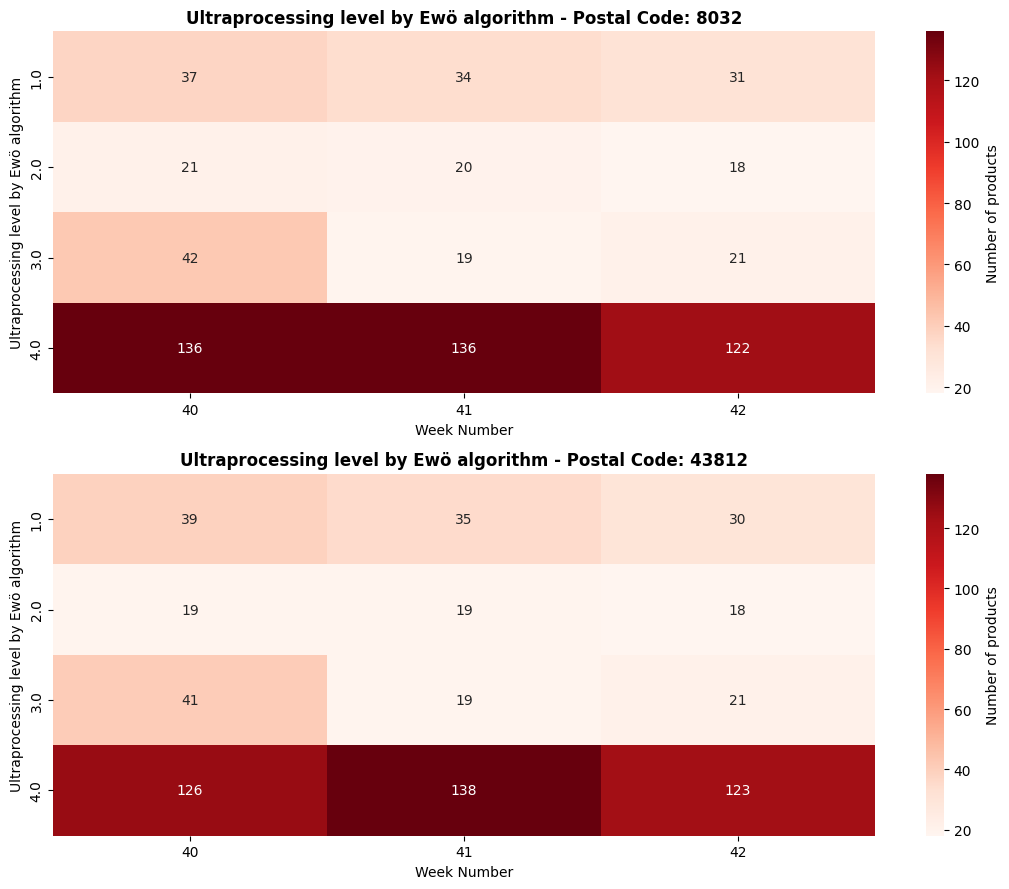

In [43]:
plot_score_distribution_by_postal_code(
    df=df_products, 
    score_col='ewo_ultra_processed_punctuation', 
    score_name='Ultraprocessing level by Ewö algorithm', 
    level_order=list(df_products['ewo_ultra_processed_punctuation'].dropna().unique()),
    cmap='Reds'
)

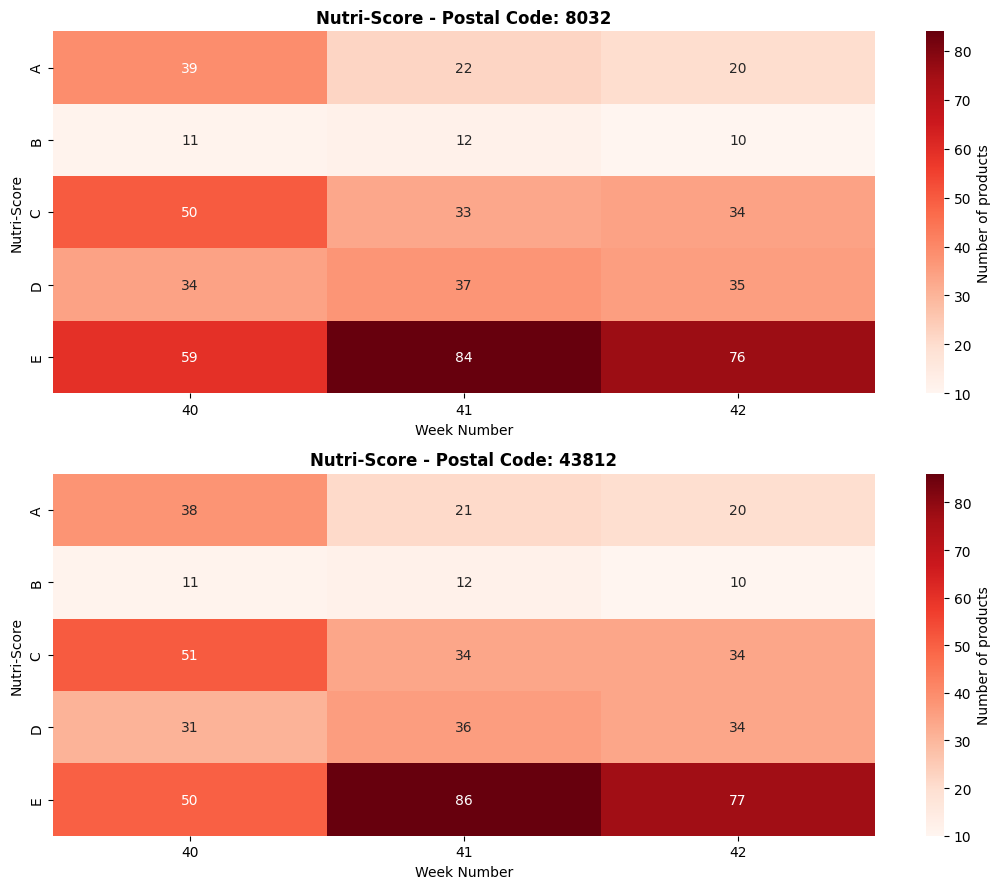

In [44]:
plot_score_distribution_by_postal_code(
    df=df_products, 
    score_col='nutriscore', 
    score_name='Nutri-Score', 
    level_order=list(df_products['nutriscore'].dropna().unique()),
    cmap='Reds'
)

### 3.3.3. Information about homepage sections

In [45]:
def generate_homepage_sections_table(
    df, section_col='title_category_main_page'
):
    """Genera la taula sol·licitada per les tutores:

    Homepage Sections | Week | Number of products | Nutri-Score | Ewö |
    Planet-Score
    """
    has_planet_data = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    # 2. Filtrem només els productes que apareixen en alguna secció de la Homepage
    df_home = df[df[section_col].notna()].copy()

    # 3. Agrupem per Secció i Setmana
    rows = []
    grouped = df_home.groupby([section_col, 'week_num'], observed=True)

    for (section, week), group in grouped:
        n_products = len(group)

        # Nutri-Score (Mean; SD) -> 1=A, 5=E
        nutri_s = group['nutriscore_num'].dropna()
        nutri_str = (
            f'{nutri_s.mean():.2f} ({nutri_s.std():.2f})'
            if len(nutri_s) > 1
            else (f'{nutri_s.mean():.2f}' if len(nutri_s) == 1 else 'N/A')
        )

        # EWÖ (Mean; SD) -> 1=Mínim, 4=Ultraprocessat
        ewo_s = group['ewo_ultra_processed_punctuation'].dropna()
        ewo_str = (
            f'{ewo_s.mean():.2f} ({ewo_s.std():.2f})'
            if len(ewo_s) > 1
            else (f'{ewo_s.mean():.2f}' if len(ewo_s) == 1 else 'N/A')
        )

        # Planet-Score (Mean; SD) -> 1=A, 5=E
        if has_planet_data:
            planet_s = group['planetscore_num'].dropna()
            planet_str = (
                f'{planet_s.mean():.2f} ({planet_s.std():.2f})'
                if len(planet_s) > 1
                else (f'{planet_s.mean():.2f}' if len(planet_s) == 1 else 'N/A')
            )
        else:
            planet_str = 'Pending'

        rows.append({
            'Homepage Sections': section,
            'Week': week,
            'Number of products': n_products,
            'Nutri-Score (Mean, SD)': nutri_str,
            'Ewö (Mean, SD)': ewo_str,
            'Planet-Score (Mean, SD)': planet_str,
        })

    return pd.DataFrame(rows)


# Execució de la taula
homepage_table_df = generate_homepage_sections_table(df_products)
homepage_table_df

,Homepage Sections,Week,Number of products,"Nutri-Score (Mean, SD)","Ewö (Mean, SD)","Planet-Score (Mean, SD)"
0,Bajadas de precio,40,227,3.76 (1.22),3.51 (0.86),Pending
1,Bajadas de precio,41,248,3.32 (1.40),3.27 (1.05),Pending
2,Bajadas de precio,42,234,3.26 (1.35),3.27 (1.03),Pending
3,Han vuelto,40,42,4.04 (1.34),2.57 (1.42),Pending
4,Han vuelto,41,71,4.08 (1.23),2.92 (1.34),Pending
5,Han vuelto,42,58,4.29 (1.13),3.00 (1.31),Pending
6,Novedades,40,68,3.97 (1.21),3.57 (0.99),Pending
7,Novedades,41,88,3.99 (1.33),3.32 (1.19),Pending
8,Novedades,42,82,3.94 (1.36),3.21 (1.20),Pending
9,Productos del momento,40,168,2.12 (1.22),2.74 (1.19),Pending


## 3.4. Product characteristics by healthiness and environmental sustainability

In [46]:
def generate_healthiness_sustainability_homepage_table(
    df, section_col='title_category_main_page'
):
    """Genera la taula de característiques de salut i sostenibilitat ambiental

    agrupada per les seccions destacades de la pàgina principal (Homepage
    Sections).
    """

    has_planet = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )


    # 2. Filtrem només els productes que pertanyen a alguna secció de la Homepage
    df_home = df[df[section_col].notna()].copy()

    rows = []

    # 3. Agrupem per Secció de la Homepage
    for section_name, group in df_home.groupby(section_col, observed=True):
        n_products = len(group)

        # Nutri-Score (Mean; SD) -> 1=A, 5=E
        nutri_s = group['nutriscore_num'].dropna()
        nutri_str = (
            f'{nutri_s.mean():.2f} ({nutri_s.std():.2f})'
            if len(nutri_s) > 1
            else (f'{nutri_s.mean():.2f}' if len(nutri_s) == 1 else 'N/A')
        )

        # EWÖ (Mean; SD) -> 1=Mínim, 4=Ultraprocessat
        ewo_s = group['ewo_ultra_processed_punctuation'].dropna()
        ewo_str = (
            f'{ewo_s.mean():.2f} ({ewo_s.std():.2f})'
            if len(ewo_s) > 1
            else (f'{ewo_s.mean():.2f}' if len(ewo_s) == 1 else 'N/A')
        )

        # Planet-Score (Mean; SD) -> 1=A, 5=E
        if has_planet:
            planet_s = group['planetscore_num'].dropna()
            planet_str = (
                f'{planet_s.mean():.2f} ({planet_s.std():.2f})'
                if len(planet_s) > 1
                else (f'{planet_s.mean():.2f}' if len(planet_s) == 1 else 'N/A')
            )
        else:
            planet_str = 'Pending'

        rows.append({
            'Homepage Section': section_name,
            'Homepage (n)': n_products,
            'Nutri-Score (Mean; SD)': nutri_str,
            'Ewö (Mean; SD)': ewo_str,
            'Planet-Score (Mean; SD)': planet_str,
        })

    # 4. Fila final de resum: TOTAL HOMEPAGE
    total_n = len(df_home)
    nutri_tot = df_home['nutriscore_num'].dropna()
    ewo_tot = df_home['ewo_ultra_processed_punctuation'].dropna()

    nutri_tot_str = (
        f'{nutri_tot.mean():.2f} ({nutri_tot.std():.2f})'
        if len(nutri_tot) > 1
        else 'N/A'
    )
    ewo_tot_str = (
        f'{ewo_tot.mean():.2f} ({ewo_tot.std():.2f})'
        if len(ewo_tot) > 1
        else 'N/A'
    )

    if has_planet:
        planet_tot = df_home['planetscore_num'].dropna()
        planet_tot_str = (
            f'{planet_tot.mean():.2f} ({planet_tot.std():.2f})'
            if len(planet_tot) > 1
            else 'N/A'
        )
    else:
        planet_tot_str = 'Pending'

    rows.append({
        'Homepage Section': 'TOTAL HOMEPAGE',
        'Homepage (n)': total_n,
        'Nutri-Score (Mean; SD)': nutri_tot_str,
        'Ewö (Mean; SD)': ewo_tot_str,
        'Planet-Score (Mean; SD)': planet_tot_str,
    })

    return pd.DataFrame(rows)


# Execució de la funció
health_sustainability_homepage_df = (
    generate_healthiness_sustainability_homepage_table(df_products)
)
health_sustainability_homepage_df

,Homepage Section,Homepage (n),Nutri-Score (Mean; SD),Ewö (Mean; SD),Planet-Score (Mean; SD)
0,Bajadas de precio,709,3.44 (1.34),3.35 (0.99),Pending
1,Han vuelto,171,4.14 (1.22),2.86 (1.35),Pending
2,Novedades,238,3.96 (1.30),3.35 (1.15),Pending
3,Productos del momento,277,3.44 (1.66),2.97 (1.25),Pending
4,TOTAL HOMEPAGE,1395,3.62 (1.42),3.20 (1.15),Pending


## 3.5. Contraposition of objective variables

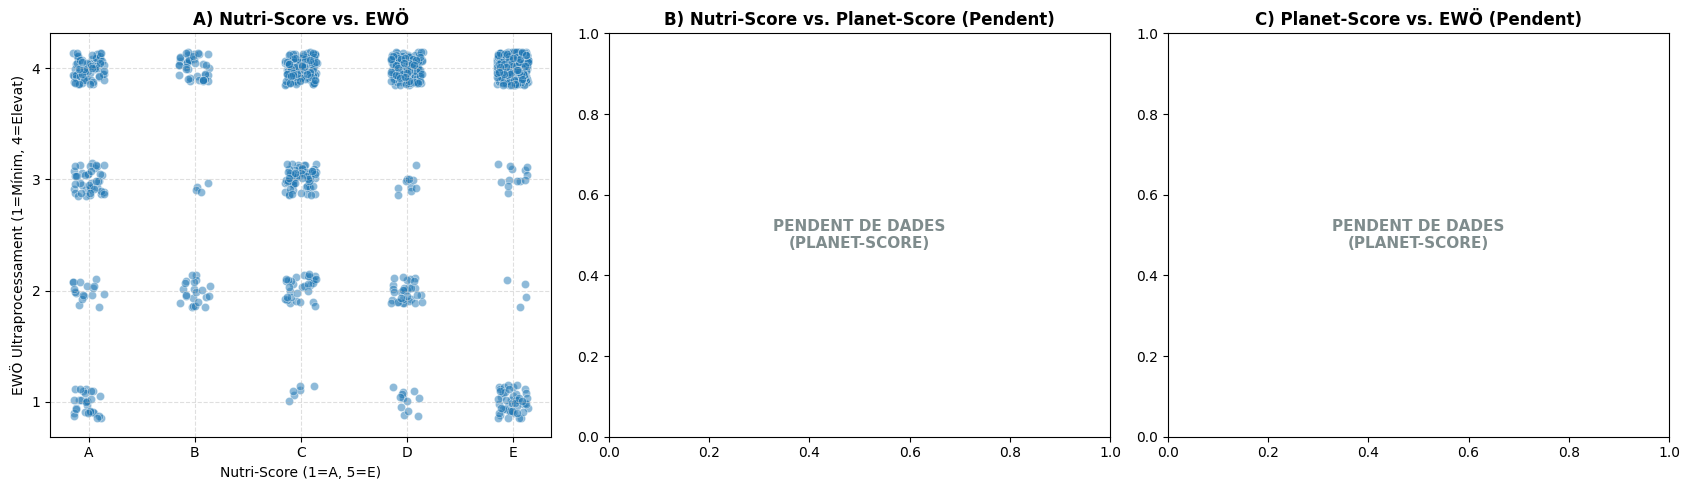

In [47]:
def plot_cross_indicator_scatters(df, hue_col=None):
    """
    Genera un panell de 3 scatter plots creuant Nutri-Score, EWÖ i Planet-Score.
    Inclou jittering per evitar el solapament de variables discretes.
    """

    has_planet = 'planetscore' in df.columns and df['planetscore'].notna().sum() > 0

    # Funció auxiliar per afegir un lleuger soroll visual (jitter)
    def add_jitter(series, amount=0.15):
        return series + np.random.uniform(-amount, amount, size=len(series))

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    # --- 1. Nutri-Score vs EWÖ ---
    data1 = df.dropna(subset=['nutriscore_num', 'ewo_ultra_processed_punctuation'])
    sns.scatterplot(
        x=add_jitter(data1['nutriscore_num']),
        y=add_jitter(data1['ewo_ultra_processed_punctuation']),
        hue=data1[hue_col] if hue_col and hue_col in data1 else None,
        alpha=0.5,
        s=35,
        ax=axes[0],
        palette='Set1' if hue_col else None
    )
    axes[0].set_title("A) Nutri-Score vs. EWÖ", fontweight='bold', fontsize=12)
    axes[0].set_xlabel("Nutri-Score (1=A, 5=E)", fontsize=10)
    axes[0].set_ylabel("EWÖ Ultraprocessament (1=Mínim, 4=Elevat)", fontsize=10)
    axes[0].set_xticks([1, 2, 3, 4, 5])
    axes[0].set_xticklabels(['A', 'B', 'C', 'D', 'E'])
    axes[0].set_yticks([1, 2, 3, 4])
    axes[0].grid(True, linestyle='--', alpha=0.4)

    # --- 2. Nutri-Score vs Planet-Score ---
    if has_planet:
        data2 = df.dropna(subset=['nutriscore_num', 'planetscore_num'])
        sns.scatterplot(
            x=add_jitter(data2['nutriscore_num']),
            y=add_jitter(data2['planetscore_num']),
            hue=data2[hue_col] if hue_col and hue_col in data2 else None,
            alpha=0.5,
            s=35,
            ax=axes[1],
            palette='Set1' if hue_col else None
        )
        axes[1].set_title("B) Nutri-Score vs. Planet-Score", fontweight='bold', fontsize=12)
        axes[1].set_xlabel("Nutri-Score (1=A, 5=E)", fontsize=10)
        axes[1].set_ylabel("Planet-Score (1=A, 5=E)", fontsize=10)
        axes[1].set_xticks([1, 2, 3, 4, 5])
        axes[1].set_xticklabels(['A', 'B', 'C', 'D', 'E'])
        axes[1].set_yticks([1, 2, 3, 4, 5])
        axes[1].set_yticklabels(['A', 'B', 'C', 'D', 'E'])
        axes[1].grid(True, linestyle='--', alpha=0.4)
    else:
        axes[1].text(0.5, 0.5, "PENDENT DE DADES\n(PLANET-SCORE)", ha='center', va='center', fontsize=11, fontweight='bold', color='#7f8c8d')
        axes[1].set_title("B) Nutri-Score vs. Planet-Score (Pendent)", fontweight='bold', fontsize=12)

    # --- 3. Planet-Score vs EWÖ ---
    if has_planet:
        data3 = df.dropna(subset=['planetscore_num', 'ewo_ultra_processed_punctuation'])
        sns.scatterplot(
            x=add_jitter(data3['planetscore_num']),
            y=add_jitter(data3['ewo_ultra_processed_punctuation']),
            hue=data3[hue_col] if hue_col and hue_col in data3 else None,
            alpha=0.5,
            s=35,
            ax=axes[2],
            palette='Set1' if hue_col else None
        )
        axes[2].set_title("C) Planet-Score vs. EWÖ", fontweight='bold', fontsize=12)
        axes[2].set_xlabel("Planet-Score (1=A, 5=E)", fontsize=10)
        axes[2].set_ylabel("EWÖ Ultraprocessament (1=Mínim, 4=Elevat)", fontsize=10)
        axes[2].set_xticks([1, 2, 3, 4, 5])
        axes[2].set_xticklabels(['A', 'B', 'C', 'D', 'E'])
        axes[2].set_yticks([1, 2, 3, 4])
        axes[2].grid(True, linestyle='--', alpha=0.4)
    else:
        axes[2].text(0.5, 0.5, "PENDENT DE DADES\n(PLANET-SCORE)", ha='center', va='center', fontsize=11, fontweight='bold', color='#7f8c8d')
        axes[2].set_title("C) Planet-Score vs. EWÖ (Pendent)", fontweight='bold', fontsize=12)

    plt.tight_layout()
    plt.show()

# Execució simple:
plot_cross_indicator_scatters(df_products)

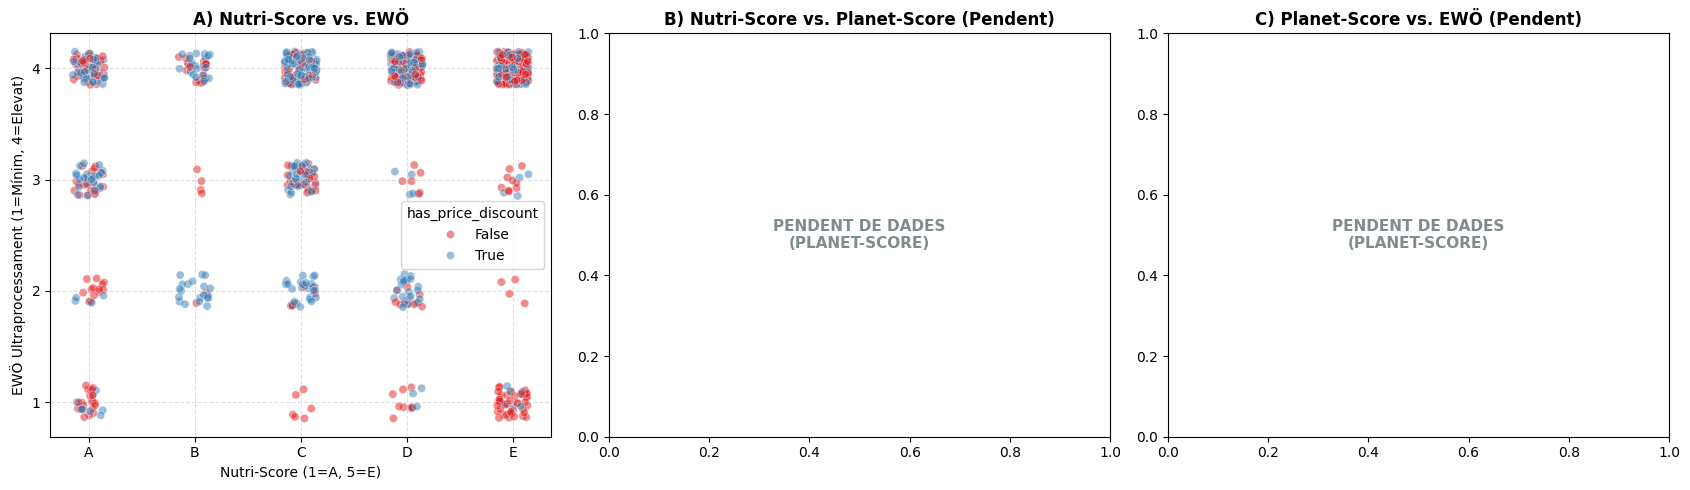

In [48]:
plot_cross_indicator_scatters(df_products, hue_col='has_price_discount')

# 4. Hypothesis test

## 4.1. Test 1: When a price discount is applied, is the mean percentage reduction on unhealthy products (D/E) greater than on healthy ones (A/B/C)?

### 4.1.1. Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1} = \mu_{2} \\
H_{1}: \mu_{1} > \mu_{2}
\end{align*}
$$

$$
\begin{align*}
\mu_{1}:\ Unhealthy\ products\ percentage\ (Nutri-Score\ D/E) \\
\mu_{2}:\ Healthy\ products\ percentage\ (Nutri-Score\ A/B/C)
\end{align*}
$$

### 4.1.2. Selection of the data

In [49]:
products_with_percentage_discount = df_products[df_products["has_price_discount"] == True]

df_unique_promo = (
    products_with_percentage_discount.groupby('id_product')
    .agg({
        'product_name': 'first',
        'nutriscore': 'first',
        'percentage_discount': 'mean',  # Descompte mitjà del producte quan s'ha promocionat
    })
    .reset_index()
)

df_unique_promo = df_unique_promo[
    df_unique_promo['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
].copy()

df_unique_promo['quality_group'] = df_unique_promo['nutriscore'].apply(
    lambda x: 'A/B/C' if x in ['A', 'B', 'C'] else 'D/E'
)

group_ab = df_unique_promo[df_unique_promo['quality_group'] == 'A/B/C']['percentage_discount']
group_de = df_unique_promo[df_unique_promo['quality_group'] == 'D/E']['percentage_discount']

### 4.1.3. Presentation of the samples and determine statistical test

In [50]:
n_ab, mean_ab, std_ab = len(group_ab), group_ab.mean(), group_ab.std()
n_de, mean_de, std_de = len(group_de), group_de.mean(), group_de.std()

print(f'Group A/B/C (Healthy): n = {n_ab}, mean = {mean_ab:.2f}%, sd = {std_ab:.2f}%')
print(f'Group D/E (Unhealthy): n = {n_de}, mean = {mean_de:.2f}%, sd = {std_de:.2f}%')

Group A/B/C (Healthy): n = 62, mean = 8.23%, sd = 6.07%
Group D/E (Unhealthy): n = 78, mean = 13.37%, sd = 8.82%


Pel teorema del límit central, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [51]:
levene_stat, levene_p = stats.levene(group_de, group_ab)

if levene_p < ALPHA:
    print("Descartem H0, per tant, les dades no tenen la mateixa variança")
else:
    print("No podem descartar H0, per tant, les dades presenten la mateixa variança")

Descartem H0, per tant, les dades no tenen la mateixa variança


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies diferents (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x_{1}} - \bar{x_{2}}}{\sqrt{\frac{s^2_{1}}{n_1}+\frac{s^2_2}{n_2}}} \sim t_{v}
$$

I té *v* graus de llibertat:

$$
v=\frac{(\frac{s^2_1}{n_1}+\frac{s^2_{2}}{n_2})^2}{\frac{(\frac{s^2_{1}}{n_1})^2}{(n_{1}-1)} + \frac{(\frac{s^2_{2}}{n_{2}})^2}{(n_2-1)}}
$$

### 4.1.4. Applying test and check hypothesis

In [52]:
t_stat, p_val = stats.ttest_ind(
    group_de,
    group_ab,
    equal_var=False,
    alternative="greater"
)

if p_val < ALPHA:
    print("Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
else:
    print("No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


## 4.2. Test 2: When a price discount is applied, are there significant differences in the average discount percentage between promoted products with Nutri-Score D/E in comparison with Nutri-Score A/B/C, stratified by postal code?

### 4.2.1. Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1,k} = \mu_{2,k} \\
H_{1}: \mu_{1,k} > \mu_{2,k} \\
k \in \{43812, 08032\}
\end{align*}
$$

$$
\begin{align*}
\mu_{1,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ unhealthy\ (Nutri-Score\ D/E)\ in\ postal\ code\ k \\
\mu_{2,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ healthy\ (Nutri-Score\ A/B/C)\ in\ postal\ code\ k \\
\end{align*}
$$

### 4.2.2. Selection of the data

In [53]:
postal_codes = sorted(products_with_percentage_discount['postal_code'].dropna().unique())

pc_data = {}

for pc in postal_codes:
    df_pc = products_with_percentage_discount[products_with_percentage_discount['postal_code'] == pc].copy()
    df_pc_unique = (
            df_pc.groupby('id_product')
            .agg({'nutriscore': 'first', 'percentage_discount': 'mean'})
            .reset_index()
        )

    df_pc_selected = df_pc_unique[
        df_pc_unique['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
    ].copy()
    df_pc_selected['quality_group'] = df_pc_selected['nutriscore'].apply(
        lambda x: 'A/B/C' if x in ['A', 'B', 'C'] else 'D/E'
    )

    group_abc = df_pc_selected[df_pc_selected['quality_group'] == 'A/B/C']['percentage_discount'].dropna()
    group_de = df_pc_selected[df_pc_selected['quality_group'] == 'D/E']['percentage_discount'].dropna()
    
    pc_data[int(pc)] = {'group_abc': group_abc, 'group_de': group_de }

### 4.2.3. Presentation of the samples and determine statistical test

In [54]:
# 1. Quants registres hi ha per a cada Codi Postal?
print("--- Volum de registres per Codi Postal ---")
print(products_with_percentage_discount['postal_code'].value_counts())

# 2. Quants productes únics té cada Codi Postal?
cp_8032 = set(
    products_with_percentage_discount[
        products_with_percentage_discount['postal_code'] == 8032
    ]['id_product']
)
cp_43812 = set(
    products_with_percentage_discount[
        products_with_percentage_discount['postal_code'] == 43812
    ]['id_product']
)

print("\n--- Productes Únics ---")
print(f'Productes a CP 8032:  {len(cp_8032)}')
print(f'Productes a CP 43812: {len(cp_43812)}')
print(f'Coincidències exactes: {len(cp_8032.intersection(cp_43812))}')

--- Volum de registres per Codi Postal ---
postal_code
8032     360
43812    359
Name: count, dtype: int64

--- Productes Únics ---
Productes a CP 8032:  188
Productes a CP 43812: 187
Coincidències exactes: 187


In [55]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    n_abc, mean_abc, std_abc = (len(group_abc),group_abc.mean(),group_abc.std())
    n_de, mean_de, std_de = (len(group_de), group_de.mean(), group_de.std())
    
    print(f"Postal code {pc}:\n Group healthy (A/B/C) n={n_abc}, mean={mean_abc}%, sd={std_abc}%\n Group unhealthy (D/E) n={n_de}, mean={mean_de}%, sd={std_de}")

Postal code 8032:
 Group healthy (A/B/C) n=62, mean=8.232392473118281%, sd=6.069387372728309%
 Group unhealthy (D/E) n=78, mean=13.37192307692308%, sd=8.819031230138705
Postal code 43812:
 Group healthy (A/B/C) n=62, mean=8.232392473118281%, sd=6.069387372728309%
 Group unhealthy (D/E) n=78, mean=13.37192307692308%, sd=8.819031230138705


Pel teorema del límit central, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [56]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    levene_stats, levene_p = stats.levene(group_de, group_abc)
    if levene_p < ALPHA:
        print(f"{pc} - Descartem H0. Les variancies no son iguals.")
    else:
        print(f"{pc} - No podem descartar H0. Les variances son iguals.")

8032 - Descartem H0. Les variancies no son iguals.
43812 - Descartem H0. Les variancies no son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies diferents (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x_{1}} - \bar{x_{2}}}{\sqrt{\frac{s^2_{1}}{n_1}+\frac{s^2_2}{n_2}}} \sim t_{v}
$$

I té *v* graus de llibertat:

$$
v=\frac{(\frac{s^2_1}{n_1}+\frac{s^2_{2}}{n_2})^2}{\frac{(\frac{s^2_{1}}{n_1})^2}{(n_{1}-1)} + \frac{(\frac{s^2_{2}}{n_{2}})^2}{(n_2-1)}}
$$

### 4.1.4. Applying test and check hypothesis

In [57]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']
    t_stat, p_val = stats.ttest_ind(
        group_de,
        group_ab,
        equal_var=False,
        alternative="greater"
    )
    
    if p_val < ALPHA:
        print(f"{pc} - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
    else:
        print(f"{pc} - No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

8032 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.
43812 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


## 4.3. Algo a fer pel planet score?...

# 5. Machine learning approach: Unsupervised clustering by K-Means

TODO quan tingui les dades de planet-score...

* Reducción de la dimensionalidad (PCA/t-SNE/UMAP)? No hace falta porque ya tengo pocas dimencionalidades (variables: planetscore, nutriscore y ewo)
* Preprocesado normalizando los datos con StandardScaler()
* Aplicar elbow rule para el k-means con el SSE para distintos valores de k.
* Clustering de Perfiles del Producto (Nutrición vs. Sostenibilidad): En lugar de agrupar por categorías del supermercado (que ya las conocemos), introducir en el clúster las variables de nutri-score (A=1, E=5), planet-score (A=1, E=5) y Ewö. Como resultado esperado podría ser que el algoritmo descubriese distintos clústeres: "Eco-Healthy" (alt planet, alt nutri), "Ultra-processed & Polluting" (baix planet, baix nutri, alt Ewö), "Greenwashed" (bon planet-score però ultraprocessat), etc. 
* Pintarlo puede que con una reducción de dimensionalidad a 2D con UMAP / PCA para representar los grupos --> no se si cal, pq puc pintar-ho tal qual en 2D i un color pel planet-score.
* Analizar los enciertos/errores:
    * SSE error.
    * Silhouette Score: Indica qué tan separados están los clusters entre sí (los valores que se aproximan a 1 son los ideales).
    * Calinski-Harabasz Index: Evalúa la dispersión intra-clúster y inter-clúster
